# Логистическая регрессия и выбор порога по F2

Одна модель — одна тетрадь. Две независимые цели: `failure_within_30d`
и `fault_type`; диагноз не зависит от решения модели отказа.
`required_route`, `severity`, `id` и обе цели исключены из входов.

40 табличных и 24 текстовых классификатора, два частотных контроля:
**66 обучений**. Конфигурации выбираются по validation AP / macro-F1.
Затем для трёх выбранных моделей отказа и контроля выбирается F2-порог.
Пороговый объект использует готовую модель без дополнительного fit.
Все исходные прогнозы при пороге 0,5 сохраняются. Test не оценивается.

Настройки и пороги выбираются на одной validation: оценки и интервалы
условны относительно этого выбора и могут быть оптимистичными.
Шесть общих текстовых шаблонов ограничивают перенос на новые формулировки.
Авторство участников требуется подтвердить; реализация подготовлена
агентом по решениям пользователя, EDA команды сохранён отдельно.


## 1. Окружение и единая конфигурация

Python 3.11 из `.venv`, локальный MLflow и один JSON с настройками всех вариантов модели.

In [1]:
import hashlib
import json
import logging
import os
import pickle
import platform
import shutil
import sys
import warnings
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    precision_recall_curve,
    roc_curve,
)
from sklearn.model_selection import FixedThresholdClassifier, ParameterGrid

PROJECT_ROOT = Path("../..").resolve()
CONFIG_PATH = PROJECT_ROOT / "configs/baseline_logistic_regression.json"
assert CONFIG_PATH.is_file(), "Рабочий каталог — notebooks/experiments/."
assert sys.version_info[:2] == (3, 11)
assert Path(sys.prefix).resolve() == PROJECT_ROOT / ".venv"
os.environ["MLFLOW_DISABLE_TELEMETRY"] = "true"
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
sys.path.insert(0, str(PROJECT_ROOT / "src"))

In [2]:
import mlflow

from industrial_maintenance import baseline, data
from industrial_maintenance import comparison as comparison_tools

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.family": "DejaVu Sans"})
CONFIG = json.loads(CONFIG_PATH.read_text(encoding="utf-8"))
dataset_config = json.loads(
    (PROJECT_ROOT / CONFIG["dataset_config"]).read_text(encoding="utf-8")
)
versions = {
    name: version(name)
    for name in ["numpy", "pandas", "scikit-learn", "mlflow", "scipy"]
}
display(pd.Series(versions, name="Версия"))
display(CONFIG)

numpy            2.4.6
pandas           3.0.6
scikit-learn     1.9.1
mlflow          3.17.1
scipy           1.17.1
Name: Версия, dtype: str

{'experiment_name': 'case_1_logistic_restricted_f2_validation',
 'dataset_config': 'configs/eda_16_10.json',
 'membership_file': 'Data/splits/eda_v1/membership.csv',
 'split_manifest': 'Data/splits/eda_v1/manifest.json',
 'membership_sha256': '7df958804864a5e37776843f66ab7ab358b74a685188df14f60eb83cddea00b1',
 'notebook': 'notebooks/experiments/01_logistic_regression.ipynb',
 'output_root': 'artifacts/experiments',
 'tracking_database': 'artifacts/tracking/mlflow.db',
 'tracking_artifacts': 'artifacts/tracking/mlflow_artifacts',
 'seed': 42,
 'binary_threshold': 0.5,
 'selection_decimals': 12,
 'error_examples': 10,
 'targets': {'failure_within_30d': 'average_precision',
  'fault_type': 'macro_f1'},
 'feature_variants': {'A_numeric': {'numeric': ['operating_hours',
    'temperature_c',
    'vibration_mm_s',
    'pressure_bar',
    'load_ratio'],
   'categorical': []},
  'A_tabular_restricted': {'numeric': ['operating_hours',
    'temperature_c',
    'vibration_mm_s',
    'pressure_bar'

## 2. Новый каталог результатов

Существующие оценённые результаты не перезаписываются. Все варианты текущего выполнения записываются в одну группу запусков MLflow.

In [3]:
started_at = datetime.now(timezone.utc)
started_clock = perf_counter()
batch_id = CONFIG["batch_prefix"] + started_at.strftime("%Y%m%dT%H%M%S_%fZ")
batch_directory = PROJECT_ROOT / CONFIG["output_root"] / batch_id
batch_directory.mkdir(parents=True, exist_ok=False)
logger = logging.getLogger(CONFIG["experiment_name"])
for old_handler in list(logger.handlers):
    old_handler.close()
    logger.removeHandler(old_handler)
logger.setLevel(logging.INFO)
logger.propagate = False
formatter = logging.Formatter("%(asctime)s %(levelname)s %(message)s")
for handler in [
    logging.StreamHandler(sys.stdout),
    logging.FileHandler(batch_directory / "run.log", encoding="utf-8"),
]:
    handler.setFormatter(formatter)
    logger.addHandler(handler)

tracking_database = PROJECT_ROOT / CONFIG["tracking_database"]
tracking_database.parent.mkdir(parents=True, exist_ok=True)
tracking_artifacts = PROJECT_ROOT / CONFIG["tracking_artifacts"]
tracking_artifacts.mkdir(parents=True, exist_ok=True)
tracking_uri = "sqlite:///" + tracking_database.as_posix()
mlflow.set_tracking_uri(tracking_uri)
existing_experiment = mlflow.get_experiment_by_name(CONFIG["experiment_name"])
if existing_experiment is None:
    experiment_id = mlflow.create_experiment(
        CONFIG["experiment_name"],
        artifact_location=tracking_artifacts.as_uri(),
    )
else:
    experiment_id = existing_experiment.experiment_id
(batch_directory / "config.json").write_text(
    json.dumps(CONFIG, ensure_ascii=False, indent=2), encoding="utf-8"
)
logger.info("Начало эксперимента: %s", batch_id)

2026-10-17 23:11:23,692 INFO Начало эксперимента: logistic_restricted_f2_20261017T201122_790479Z


## 3. Данные, разбиение и состав входов

Используется неизменяемый CSV и сохранённое разбиение eda_v1. Предобработка обучается исключительно на train. Для исследования используются только train и validation.

In [4]:
source_frame, source_manifest = data.load_dataset(PROJECT_ROOT, dataset_config)
membership_path = PROJECT_ROOT / CONFIG["membership_file"]
split_manifest_path = PROJECT_ROOT / CONFIG["split_manifest"]
assert data.file_sha256(membership_path) == CONFIG["membership_sha256"]
split_manifest = json.loads(split_manifest_path.read_text(encoding="utf-8"))
assert split_manifest["membership_sha256"] == CONFIG["membership_sha256"]
assert split_manifest["protocol"]["sha256"] == dataset_config["sha256"]
membership = pd.read_csv(
    membership_path, dtype={"id": "string", "group_id": "string"}
)
data.validate_splits(source_frame, membership)
train_ids = membership.loc[membership["split"].eq("train"), "id"]
validation_ids = membership.loc[membership["split"].eq("validation"), "id"]
train = source_frame.loc[source_frame["id"].isin(train_ids)].copy()
validation = source_frame.loc[source_frame["id"].isin(validation_ids)].copy()
del source_frame
assert set(train["id"]).isdisjoint(validation["id"])
assert len(train) == split_manifest["sizes"]["train"]
assert len(validation) == split_manifest["sizes"]["validation"]
display(pd.Series(split_manifest["sizes"], name="Размер выборки"))
for target in CONFIG["targets"]:
    assert set(validation[target]).issubset(set(train[target]))
    display(
        pd.DataFrame(
            {
                "train": train[target].value_counts(),
                "validation": validation[target].value_counts(),
            }
        )
    )
logger.info(
    "Train=%s; validation=%s; test не оценивается", len(train), len(validation)
)

train         10655
validation     2193
test           2152
Name: Размер выборки, dtype: int64

,train,validation
failure_within_30d,,
0,8870,1830
1,1785,363


,train,validation
fault_type,,
bearing_wear,1261,255
cavitation,1069,222
imbalance,1147,232
normal,4783,1005
overheat,1215,252
seal_leak,1180,227


2026-10-17 23:11:23,923 INFO Train=10655; validation=2193; test не оценивается


In [5]:
feature_records = []
for variant, groups in CONFIG["feature_variants"].items():
    for kind, columns in groups.items():
        for column in columns:
            assert column not in CONFIG["excluded_features"]
            assert (
                dataset_config["availability"][column]
                == "available_by_assumption"
            )
            feature_records.append(
                {"variant": variant, "kind": kind, "field": column}
            )
    features = [field for fields in groups.values() for field in fields]
    assert not {"id", *CONFIG["targets"]}.intersection(features)
    for sample in [train, validation]:
        assert not sample[features].isna().any().any()
        if "numeric" in groups:
            assert np.isfinite(sample[groups["numeric"]].to_numpy()).all()
        else:
            assert sample["operator_log"].str.strip().ne("").all()
pd.DataFrame(feature_records).to_csv(
    batch_directory / "feature_variants.csv", index=False
)
display(pd.DataFrame(feature_records))

notebook_path = PROJECT_ROOT / CONFIG["notebook"]
notebook_document = json.loads(notebook_path.read_text(encoding="utf-8"))
source_cells = [
    {"cell_type": cell["cell_type"], "source": "".join(cell["source"])}
    for cell in notebook_document["cells"]
]
source_payload = json.dumps(source_cells, ensure_ascii=False).encode("utf-8")
(batch_directory / "notebook_source.json").write_bytes(source_payload)
source_directory = batch_directory / "source"
source_directory.mkdir()
source_checksums = {}
for module in [baseline, data, comparison_tools]:
    module_path = Path(module.__file__)
    shutil.copy2(module_path, source_directory / module_path.name)
    source_checksums[module_path.name] = data.file_sha256(module_path)
for name in ["pyproject.toml", "uv.lock"]:
    shutil.copy2(PROJECT_ROOT / name, source_directory / name)
manifest = {
    "batch_id": batch_id,
    "status": "running",
    "started_at_utc": started_at.isoformat(),
    "python": sys.version,
    "platform": platform.platform(),
    "libraries": versions,
    "config": CONFIG,
    "dataset_config": dataset_config,
    "source": source_manifest,
    "split": split_manifest,
    "source_checksums": source_checksums,
    "notebook_source_sha256": hashlib.sha256(source_payload).hexdigest(),
    "config_sha256": data.file_sha256(CONFIG_PATH),
    "test_evaluated": False,
    "selection_scope": "validation; train only for fitting",
    "tracking_uri": tracking_uri,
    "authors": "Фактическое авторство участников требует подтверждения",
}
manifest_path = batch_directory / "manifest.json"
manifest_path.write_text(
    json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8"
)
manifest["hardware"] = {
    "processor": platform.processor(),
    "machine": platform.machine(),
    "logical_cpus": os.cpu_count(),
    "training_device": "CPU",
}

,variant,kind,field
0,A_numeric,numeric,operating_hours
1,A_numeric,numeric,temperature_c
2,A_numeric,numeric,vibration_mm_s
3,A_numeric,numeric,pressure_bar
4,A_numeric,numeric,load_ratio
5,A_tabular_restricted,numeric,operating_hours
6,A_tabular_restricted,numeric,temperature_c
7,A_tabular_restricted,numeric,vibration_mm_s
8,A_tabular_restricted,numeric,pressure_bar
9,A_tabular_restricted,numeric,load_ratio


## 4. Табличные настройки и TF-IDF

- `A_numeric`: operating_hours, temperature_c, vibration_mm_s,
  pressure_bar, load_ratio.
- `A_tabular_restricted`: те же показания, horizon_days, equipment, manual_id.
- `T0_tfidf`: только исходный operator_log → TF-IDF → логистическая регрессия.

Табличный поиск: пять C × два варианта весов × два набора входов × две цели
= 40 моделей. Отдельно сохраняется выбор из первоначального диапазона
C=0.1/1/10, чтобы оценить пользу расширения поиска.
Текст: 24 настройки, униграммы или униграммы с биграммами,
C=0.1/1/10, веса None/balanced, две цели.

Прежние абляции, возвращавшие исключённые поля, удалены из активного опыта.
Остальные настройки сохранены: числовая стандартизация, one-hot для категорий;
TF-IDF по словам с нижним регистром, min_df=2, max_df=1.0,
sublinear_tf=True, нормализация L2. Словарь и IDF — только по train.


In [6]:
experiment_tasks = []
for target in CONFIG["targets"]:
    for variant in CONFIG["search_variants"]:
        for parameters in ParameterGrid(CONFIG["search"]):
            experiment_tasks.append(
                {
                    "target": target,
                    "variant": variant,
                    "kind": "tabular",
                    **parameters,
                }
            )
    for parameters in ParameterGrid(CONFIG["tfidf_search"]):
        experiment_tasks.append(
            {
                "target": target,
                "variant": "T0_tfidf",
                "kind": "text",
                **parameters,
            }
        )
assert len(experiment_tasks) == CONFIG["expected_classifier_runs"]
display(pd.DataFrame(experiment_tasks))

,target,variant,kind,C,class_weight,ngram_range
0,failure_within_30d,A_numeric,tabular,0.001,NaN,NaN
1,failure_within_30d,A_numeric,tabular,0.001,balanced,NaN
2,failure_within_30d,A_numeric,tabular,0.010,NaN,NaN
3,failure_within_30d,A_numeric,tabular,0.010,balanced,NaN
4,failure_within_30d,A_numeric,tabular,0.100,NaN,NaN
...,...,...,...,...,...,...
59,fault_type,T0_tfidf,text,1.000,balanced,"[1, 2]"
60,fault_type,T0_tfidf,text,10.000,NaN,"[1, 1]"
61,fault_type,T0_tfidf,text,10.000,NaN,"[1, 2]"
62,fault_type,T0_tfidf,text,10.000,balanced,"[1, 1]"


In [7]:
search_records = []
for task in experiment_tasks:
    target = task["target"]
    variant = task["variant"]
    groups = CONFIG["feature_variants"][variant]
    features = [field for fields in groups.values() for field in fields]
    parameters = {
        **CONFIG["model_parameters"],
        "C": task["C"],
        "class_weight": task["class_weight"],
    }
    vectorizer_parameters = None
    if task["kind"] == "text":
        vectorizer_parameters = {
            **CONFIG["tfidf_parameters"],
            "ngram_range": tuple(task["ngram_range"]),
        }
        pipeline = baseline.build_text_pipeline(
            vectorizer_parameters, parameters
        )
        train_inputs = train["operator_log"]
    else:
        pipeline = baseline.build_logistic_pipeline(
            groups["numeric"], groups["categorical"], parameters
        )
        train_inputs = train[features]
    weight_name = task["class_weight"] or "none"
    run_name = f"{target}__{variant}__C{task['C']}__{weight_name}"
    if vectorizer_parameters:
        run_name += f"__ngram{task['ngram_range'][1]}"
    with mlflow.start_run(
        experiment_id=experiment_id,
        run_name=run_name,
        tags={
            "batch_id": batch_id,
            "target": target,
            "variant": variant,
            "kind": task["kind"],
        },
    ) as active_run:
        run_id = active_run.info.run_id
        run_directory = batch_directory / "runs" / run_id
        run_directory.mkdir(parents=True)
        run_path = run_directory.relative_to(PROJECT_ROOT).as_posix()
        logger.info("Обучение %s; run_id=%s", run_name, run_id)
        fit_started = perf_counter()
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always", ConvergenceWarning)
            pipeline.fit(train_inputs, train[target])
        fit_seconds = perf_counter() - fit_started
        convergence_warnings = [
            str(item.message)
            for item in caught
            if issubclass(item.category, ConvergenceWarning)
        ]
        for item in caught:
            logger.warning("%s: %s", item.category.__name__, item.message)
        classes = pipeline.named_steps["classifier"].classes_.tolist()
        record = {
            "run_id": run_id,
            "run_path": run_path,
            "target": target,
            "variant": variant,
            "kind": task["kind"],
            "C": task["C"],
            "class_weight": weight_name,
            "class_weight_order": int(task["class_weight"] is not None),
            "fit_seconds": fit_seconds,
            "converged": not convergence_warnings,
            "ngram_max": 0,
            "max_n_iter": int(
                pipeline.named_steps["classifier"].n_iter_.max()
            ),
        }
        if vectorizer_parameters:
            record["ngram_max"] = task["ngram_range"][1]
            record["vocabulary_size"] = len(
                pipeline.named_steps["tfidf"].vocabulary_
            )
        metric_sets = {}
        for partition, sample in [
            ("train", train),
            ("validation", validation),
        ]:
            inputs = (
                sample["operator_log"]
                if vectorizer_parameters
                else sample[features]
            )
            predictions = baseline.prediction_table(
                sample["id"],
                sample[target],
                pipeline.predict_proba(inputs),
                classes,
                target,
                CONFIG["binary_threshold"],
            )
            predictions.to_csv(
                run_directory / f"{partition}_predictions.csv", index=False
            )
            metrics = baseline.classification_metrics(
                predictions, classes, target
            )
            metric_sets[partition] = metrics
            for name, value in metrics.items():
                record[f"{partition}_{name}"] = value
        with (run_directory / "model.pkl").open("wb") as model_file:
            pickle.dump(pipeline, model_file, protocol=pickle.HIGHEST_PROTOCOL)
        trial_manifest = {
            **manifest,
            "run_id": run_id,
            "run_path": run_path,
            "status": "completed",
            "target": target,
            "variant": variant,
            "kind": task["kind"],
            "classes": classes,
            "features": features,
            "model_parameters": parameters,
            "tfidf_parameters": vectorizer_parameters,
            "metrics": metric_sets,
            "fit_seconds": fit_seconds,
            "convergence_warnings": convergence_warnings,
        }
        (run_directory / "manifest.json").write_text(
            json.dumps(trial_manifest, ensure_ascii=False, indent=2),
            encoding="utf-8",
        )
        mlflow.log_params(
            {
                **parameters,
                "target": target,
                "variant": variant,
                "kind": task["kind"],
                "features": json.dumps(features),
                "threshold": CONFIG["binary_threshold"],
                "dataset_sha256": dataset_config["sha256"],
                "membership_sha256": CONFIG["membership_sha256"],
            }
        )
        if vectorizer_parameters:
            mlflow.log_params(
                {
                    f"tfidf_{key}": value
                    for key, value in vectorizer_parameters.items()
                }
            )
            mlflow.log_metric("vocabulary_size", record["vocabulary_size"])
        mlflow.log_metrics(
            {
                name: value
                for name, value in record.items()
                if name.startswith(("train_", "validation_"))
                and value is not None
            }
        )
        mlflow.log_metric("fit_seconds", fit_seconds)
        mlflow.set_tag("converged", str(record["converged"]))
        logger.info(
            "Завершено %s; сходимость=%s", run_name, record["converged"]
        )
        shutil.copy2(batch_directory / "run.log", run_directory / "run.log")
        mlflow.log_artifacts(str(run_directory))
        mlflow.log_artifact(str(batch_directory / "config.json"))
        mlflow.log_artifact(str(batch_directory / "notebook_source.json"))
        search_records.append(record)
        pd.DataFrame(search_records).to_csv(
            batch_directory / "new_results.csv", index=False
        )
new_results = pd.DataFrame(search_records)
assert len(new_results) == CONFIG["expected_classifier_runs"]
display(new_results)

2026-10-17 23:11:24,160 INFO Обучение failure_within_30d__A_numeric__C0.001__none; run_id=6e7bc1cb575846deab4b1c55c23bd47f


2026-10-17 23:11:24,270 INFO Завершено failure_within_30d__A_numeric__C0.001__none; сходимость=True


2026-10-17 23:11:24,339 INFO Обучение failure_within_30d__A_numeric__C0.001__balanced; run_id=a2e9dc6d167244709858c509c1caa7e0


2026-10-17 23:11:24,422 INFO Завершено failure_within_30d__A_numeric__C0.001__balanced; сходимость=True


2026-10-17 23:11:24,483 INFO Обучение failure_within_30d__A_numeric__C0.01__none; run_id=49e7c094570041f2a6b6049983845dd3


...

2026-10-17 23:11:41,255 INFO Обучение fault_type__T0_tfidf__C10.0__balanced__ngram1; run_id=4d3baa5c73df40f89e164d6d05ef228b


2026-10-17 23:11:41,567 INFO Завершено fault_type__T0_tfidf__C10.0__balanced__ngram1; сходимость=True


2026-10-17 23:11:41,636 INFO Обучение fault_type__T0_tfidf__C10.0__balanced__ngram2; run_id=c98c4974c29c4b2d8e0854219591a4e0


2026-10-17 23:11:41,998 INFO Завершено fault_type__T0_tfidf__C10.0__balanced__ngram2; сходимость=True


,run_id,run_path,target,variant,kind,C,class_weight,class_weight_order,fit_seconds,converged,...,validation_accuracy,validation_macro_f1,validation_log_loss,validation_precision,validation_recall,validation_f1,validation_f2,validation_roc_auc,validation_average_precision,vocabulary_size
0,6e7bc1cb575846deab4b1c55c23bd47f,artifacts/experiments/logistic_restricted_f2_2...,failure_within_30d,A_numeric,tabular,0.001,none,0,0.032975,True,...,0.855905,0.578579,0.319685,0.960784,0.134986,0.236715,0.163007,0.908966,0.687009,NaN
1,a2e9dc6d167244709858c509c1caa7e0,artifacts/experiments/logistic_restricted_f2_2...,failure_within_30d,A_numeric,tabular,0.001,balanced,1,0.007048,True,...,0.806658,0.732440,0.449272,0.454815,0.845730,0.591522,0.721674,0.909524,0.683326,NaN
2,49e7c094570041f2a6b6049983845dd3,artifacts/experiments/logistic_restricted_f2_2...,failure_within_30d,A_numeric,tabular,0.010,none,0,0.006832,True,...,0.879161,0.734797,0.271868,0.731132,0.426997,0.539130,0.465745,0.909062,0.686583,NaN
3,f43e0eb264cb490a95c15c413d8bdc74,artifacts/experiments/logistic_restricted_f2_2...,failure_within_30d,A_numeric,tabular,0.010,balanced,1,0.007720,True,...,0.810306,0.733920,0.399985,0.459542,0.829201,0.591356,0.714286,0.909132,0.681511,NaN
4,5529d09ab7b04a1fa53bbe94d9d8d870,artifacts/experiments/logistic_restricted_f2_2...,failure_within_30d,A_numeric,tabular,0.100,none,0,0.007167,True,...,0.880529,0.753925,0.267514,0.696498,0.493113,0.577419,0.523698,0.908942,0.685703,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59,8fd94555ccde47c780c7342cdd8117e9,artifacts/experiments/logistic_restricted_f2_2...,fault_type,T0_tfidf,text,1.000,balanced,1,0.109035,True,...,1.000000,1.000000,0.008707,NaN,NaN,NaN,NaN,NaN,NaN,217.0
60,685283e93dd84e5eb4fd544ea342bc76,artifacts/experiments/logistic_restricted_f2_2...,fault_type,T0_tfidf,text,10.000,none,0,0.074794,True,...,1.000000,1.000000,0.001127,NaN,NaN,NaN,NaN,NaN,NaN,108.0
61,989065c7d52b472899ae2749e9ec7a02,artifacts/experiments/logistic_restricted_f2_2...,fault_type,T0_tfidf,text,10.000,none,0,0.103582,True,...,1.000000,1.000000,0.001112,NaN,NaN,NaN,NaN,NaN,NaN,217.0
62,4d3baa5c73df40f89e164d6d05ef228b,artifacts/experiments/logistic_restricted_f2_2...,fault_type,T0_tfidf,text,10.000,balanced,1,0.075535,True,...,1.000000,1.000000,0.002160,NaN,NaN,NaN,NaN,NaN,NaN,108.0


## 5. Частотные контроли

Два DummyClassifier(strategy="prior") обучаются на том же train, по одному на цель. Предобработка и модель сравнения не получают validation при обучении.

In [8]:
reference_records = []
for target in CONFIG["targets"]:
    reference = DummyClassifier(
        strategy=CONFIG["reference"]["strategy"], random_state=CONFIG["seed"]
    )
    with mlflow.start_run(
        experiment_id=experiment_id,
        run_name=f"{target}__prior",
        tags={"batch_id": batch_id, "target": target, "variant": "prior"},
    ) as active_run:
        run_id = active_run.info.run_id
        run_directory = batch_directory / "runs" / run_id
        run_directory.mkdir(parents=True)
        fit_started = perf_counter()
        reference.fit(train[["operating_hours"]], train[target])
        fit_seconds = perf_counter() - fit_started
        classes = reference.classes_.tolist()
        record = {
            "run_id": run_id,
            "run_path": run_directory.relative_to(PROJECT_ROOT).as_posix(),
            "target": target,
            "variant": "prior",
            "fit_seconds": fit_seconds,
        }
        metric_sets = {}
        for partition, sample in [
            ("train", train),
            ("validation", validation),
        ]:
            predictions = baseline.prediction_table(
                sample["id"],
                sample[target],
                reference.predict_proba(sample[["operating_hours"]]),
                classes,
                target,
                CONFIG["binary_threshold"],
            )
            predictions.to_csv(
                run_directory / f"{partition}_predictions.csv", index=False
            )
            metrics = baseline.classification_metrics(
                predictions, classes, target
            )
            metric_sets[partition] = metrics
            for name, value in metrics.items():
                record[f"{partition}_{name}"] = value
        with (run_directory / "model.pkl").open("wb") as model_file:
            pickle.dump(
                reference, model_file, protocol=pickle.HIGHEST_PROTOCOL
            )
        (run_directory / "manifest.json").write_text(
            json.dumps(
                {
                    **manifest,
                    "run_id": run_id,
                    "status": "completed",
                    "target": target,
                    "variant": "prior",
                    "features": ["operating_hours"],
                    "model_parameters": {
                        "strategy": CONFIG["reference"]["strategy"]
                    },
                    "classes": classes,
                    "metrics": metric_sets,
                    "fit_seconds": fit_seconds,
                },
                ensure_ascii=False,
                indent=2,
            ),
            encoding="utf-8",
        )
        mlflow.log_params(
            {"strategy": CONFIG["reference"]["strategy"], "target": target}
        )
        mlflow.log_metrics(
            {
                key: value
                for key, value in record.items()
                if (key.startswith("train_") or key.startswith("validation_"))
                and value is not None
            }
        )
        logger.info("Сохранён prior для %s; run_id=%s", target, run_id)
        shutil.copy2(batch_directory / "run.log", run_directory / "run.log")
        mlflow.log_artifacts(str(run_directory))
        reference_records.append(record)
reference_results = pd.DataFrame(reference_records)
reference_results.to_csv(
    batch_directory / "reference_results.csv", index=False
)
display(reference_results)

2026-10-17 23:11:42,147 INFO Сохранён prior для failure_within_30d; run_id=c2abf8dc3897473ab466615e5a546fb6


2026-10-17 23:11:42,330 INFO Сохранён prior для fault_type; run_id=af0c6bda51b945378cd563fe9a46f245


,run_id,run_path,target,variant,fit_seconds,train_accuracy,train_macro_f1,train_log_loss,train_precision,train_recall,...,train_average_precision,validation_accuracy,validation_macro_f1,validation_log_loss,validation_precision,validation_recall,validation_f1,validation_f2,validation_roc_auc,validation_average_precision
0,c2abf8dc3897473ab466615e5a546fb6,artifacts/experiments/logistic_restricted_f2_2...,failure_within_30d,prior,0.001416,0.832473,0.454289,0.451943,0.0,0.0,...,0.167527,0.834473,0.454884,0.448736,0.0,0.0,0.0,0.0,0.5,0.165527
1,af0c6bda51b945378cd563fe9a46f245,artifacts/experiments/logistic_restricted_f2_2...,fault_type,prior,0.004168,0.448897,0.103273,1.574034,NaN,NaN,...,NaN,0.458276,0.104753,1.561055,NaN,NaN,NaN,NaN,NaN,NaN


## 6. Выбор настроек по validation

AP — основная метрика отказа, macro-F1 — диагноза.
Сначала фиксируется выбор в первоначальном табличном диапазоне,
затем выбор среди всех настроек для каждого варианта входов.
Несошедшиеся кандидаты исключаются; отсутствие пригодных настроек — ошибка.
При равенстве до 12 знаков предпочитается меньшее C, затем отсутствие весов,
для текста затем униграммы. Начальная настройка — C=1 без весов,
для текста — униграммы. Порог не подбирается, остаётся 0,5.

F2 не участвует в выборе конфигурации. Её порог подбирается отдельно после завершения выбора по AP.

In [9]:
search_results = new_results.copy()
search_results.to_csv(batch_directory / "search_results.csv", index=False)
all_candidates = search_results.copy()
selected_records = []
for selection_scope in ["initial_range", "full_range"]:
    if selection_scope == "initial_range":
        search_results = all_candidates.loc[
            all_candidates["kind"].eq("tabular")
            & all_candidates["C"].isin(CONFIG["initial_search"]["C"])
        ].copy()
        variants_to_select = CONFIG["search_variants"]
    else:
        search_results = all_candidates.copy()
        variants_to_select = CONFIG["search_variants"] + ["T0_tfidf"]
    for target, primary_metric in CONFIG["targets"].items():
        score_column = f"validation_{primary_metric}"
        for variant in variants_to_select:
            group = search_results.loc[
                search_results["target"].eq(target)
                & search_results["variant"].eq(variant)
            ].copy()
            eligible = group.loc[
                group["converged"] & group[score_column].notna()
            ].copy()
            if eligible.empty:
                manifest["status"] = "failed"
                manifest_path.write_text(
                    json.dumps(manifest, ensure_ascii=False, indent=2),
                    encoding="utf-8",
                )
                raise ValueError(
                    f"Нет пригодных кандидатов: {target}/{variant}"
                )
            eligible["ranking_score"] = eligible[score_column].round(
                CONFIG["selection_decimals"]
            )
            sorting = ["ranking_score", "C", "class_weight_order"]
            ascending = [False, True, True]
            if variant == "T0_tfidf":
                sorting.append("ngram_max")
                ascending.append(True)
            best = (
                eligible.sort_values(
                    sorting, ascending=ascending, kind="stable"
                )
                .iloc[0]
                .to_dict()
            )
            initial_mask = group["C"].eq(
                CONFIG["initial_configuration"]["C"]
            ) & group["class_weight"].eq("none")
            if variant == "T0_tfidf":
                initial_mask &= group["ngram_max"].eq(1)
            initial = group.loc[initial_mask].iloc[0]
            best["selection_metric"] = primary_metric
            best["initial_validation_score"] = initial[score_column]
            best["selected_validation_score"] = best[score_column]
            best["validation_improvement"] = (
                best[score_column] - initial[score_column]
            )
            best["selection_scope"] = selection_scope
            selected_records.append(best)

all_selected = pd.DataFrame(selected_records)
initial_selected = all_selected.loc[
    all_selected["selection_scope"].eq("initial_range")
].copy()
selected = all_selected.loc[
    all_selected["selection_scope"].eq("full_range")
].copy()
initial_selected.to_csv(
    batch_directory / "initial_range_models.csv", index=False
)
selected.to_csv(batch_directory / "selected_models.csv", index=False)
assert len(initial_selected) == 4 and len(selected) == 6
display(selected)

,run_id,run_path,target,variant,kind,C,class_weight,class_weight_order,fit_seconds,converged,...,validation_f2,validation_roc_auc,validation_average_precision,vocabulary_size,ranking_score,selection_metric,initial_validation_score,selected_validation_score,validation_improvement,selection_scope
4,6e7bc1cb575846deab4b1c55c23bd47f,artifacts/experiments/logistic_restricted_f2_2...,failure_within_30d,A_numeric,tabular,0.001,none,0,0.032975,True,...,0.163007,0.908966,0.687009,NaN,0.687009,average_precision,0.685609,0.687009,0.001399,full_range
5,f330e64b34a2445cbb93211953ac6542,artifacts/experiments/logistic_restricted_f2_2...,failure_within_30d,A_tabular_restricted,tabular,0.001,none,0,0.020165,True,...,0.166223,0.909308,0.683601,NaN,0.683601,average_precision,0.674613,0.683601,0.008988,full_range
6,c0256cbf1a754a7d970c974b7923e481,artifacts/experiments/logistic_restricted_f2_2...,failure_within_30d,T0_tfidf,text,0.100,none,0,0.061119,True,...,0.063588,0.855282,0.442193,108.0,0.442193,average_precision,0.441289,0.442193,0.000904,full_range
7,c7a03ae5a8f142c3bb1fb392f0506fac,artifacts/experiments/logistic_restricted_f2_2...,fault_type,A_numeric,tabular,0.100,none,0,0.037152,True,...,NaN,NaN,NaN,NaN,0.770368,macro_f1,0.767950,0.770368,0.002418,full_range
8,71e68116dc904b408936c5df2ac04c71,artifacts/experiments/logistic_restricted_f2_2...,fault_type,A_tabular_restricted,tabular,0.100,none,0,0.065157,True,...,NaN,NaN,NaN,NaN,0.766584,macro_f1,0.765284,0.766584,0.001300,full_range
9,a524dbade83044728f1394cc1049ce1b,artifacts/experiments/logistic_restricted_f2_2...,fault_type,T0_tfidf,text,0.100,none,0,0.078002,True,...,NaN,NaN,NaN,108.0,1.000000,macro_f1,1.000000,1.000000,0.000000,full_range


## 7. Кривые поиска

Исходный и расширенный диапазоны показаны на общей шкале C. Текстовые представления сравниваются отдельно при том же классификаторе.

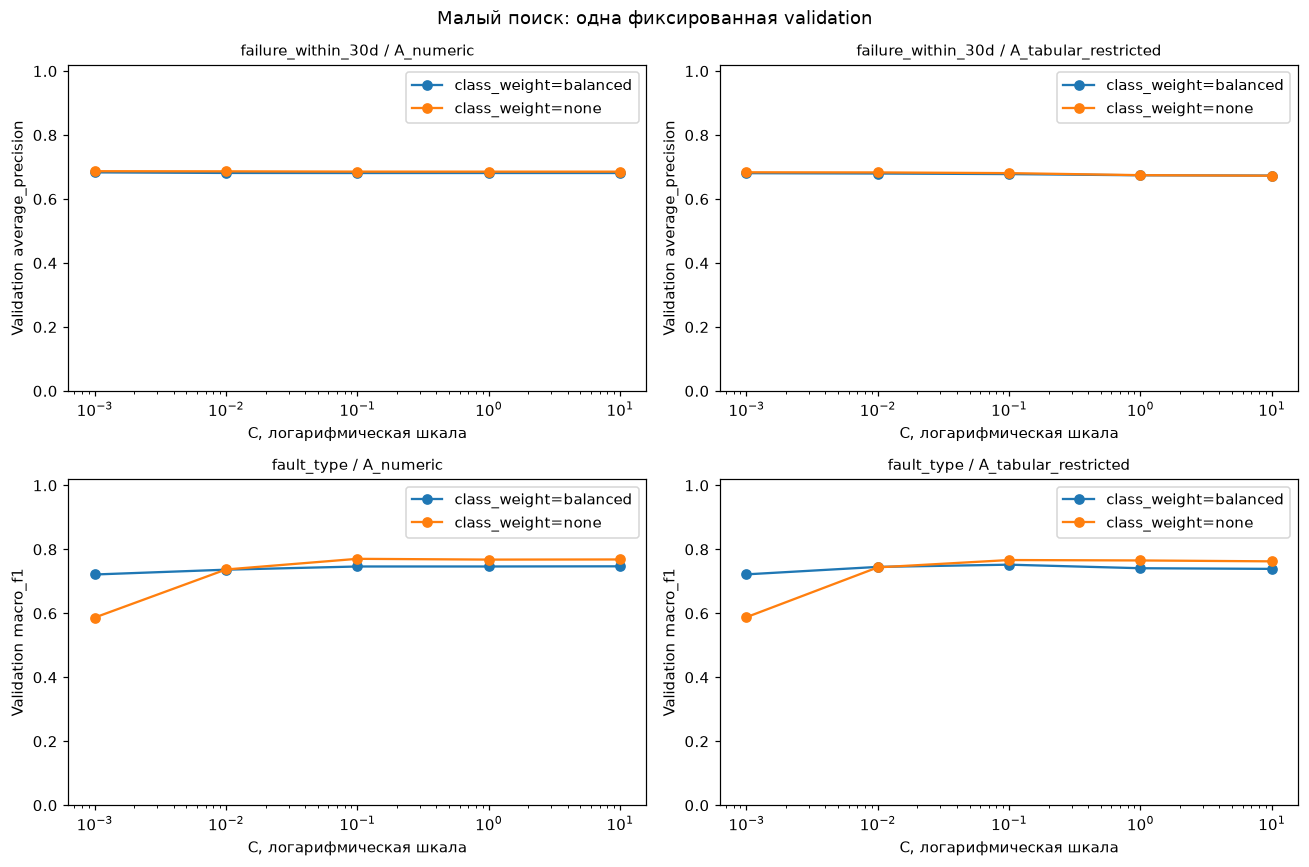

In [10]:
figure, axes = plt.subplots(2, 2, figsize=(12, 8))
for row, axis in zip(
    selected.loc[selected["kind"].eq("tabular")].to_dict("records"), axes.flat
):
    subset = search_results.loc[
        search_results["target"].eq(row["target"])
        & search_results["variant"].eq(row["variant"])
    ]
    metric = row["selection_metric"]
    for weight, curve in subset.groupby("class_weight"):
        curve = curve.sort_values("C")
        axis.plot(
            curve["C"],
            curve[f"validation_{metric}"],
            marker="o",
            label=f"class_weight={weight}",
        )
    axis.set_xscale("log")
    axis.set_xlabel("C, логарифмическая шкала")
    axis.set_ylabel(f"Validation {metric}")
    axis.set_ylim(0, 1.02)
    axis.set_title(f"{row['target']} / {row['variant']}", fontsize=10)
    axis.legend()
figure.suptitle("Малый поиск: одна фиксированная validation")
figure.tight_layout()
batch_figures = batch_directory / "figures"
batch_figures.mkdir()
figure.savefig(batch_figures / "validation_search.png")
plt.show()
plt.close(figure)

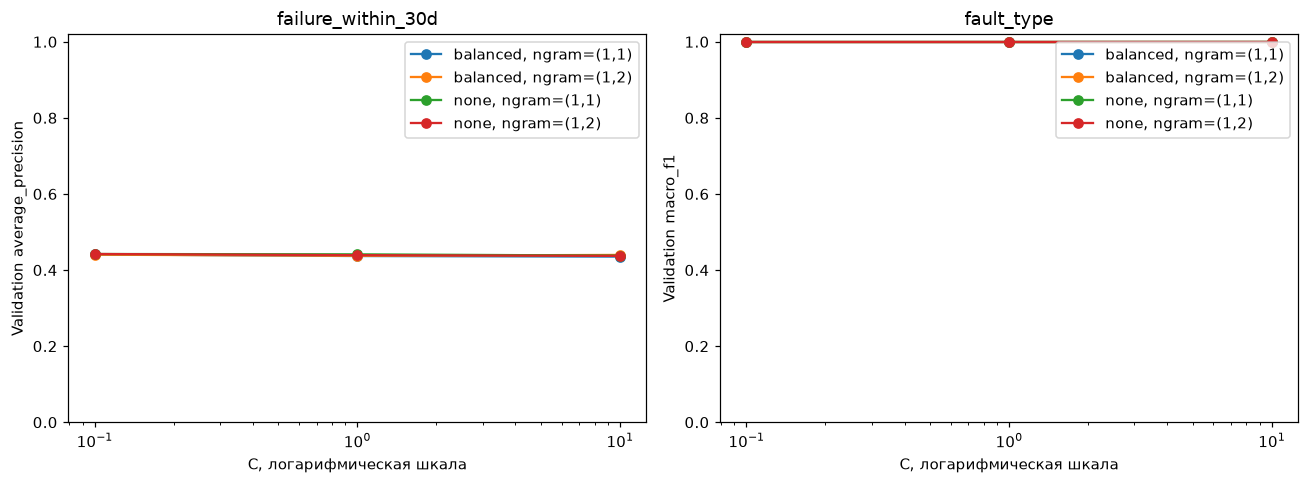

In [11]:
figure, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for row, axis in zip(
    selected.loc[selected["kind"].eq("text")].to_dict("records"), axes
):
    subset = search_results.loc[
        search_results["target"].eq(row["target"])
        & search_results["kind"].eq("text")
    ]
    metric = row["selection_metric"]
    for (weight, ngram), curve in subset.groupby(
        ["class_weight", "ngram_max"]
    ):
        curve = curve.sort_values("C")
        axis.plot(
            curve["C"],
            curve[f"validation_{metric}"],
            marker="o",
            label=f"{weight}, ngram=(1,{ngram})",
        )
    axis.set_xscale("log")
    axis.set_xlabel("C, логарифмическая шкала")
    axis.set_ylabel(f"Validation {metric}")
    axis.set_title(row["target"])
    axis.set_ylim(0, 1.02)
    axis.legend()
figure.tight_layout()
batch_figures = batch_directory / "figures"
batch_figures.mkdir(exist_ok=True)
figure.savefig(batch_figures / "text_validation_search.png")
plt.show()
plt.close(figure)

## 8. Парные сравнения и неопределённость

Четыре сравнения расширения табличного поиска и шесть сравнений текста
с выбранными табличными моделями и prior. Групповой бутстрэп:
2 000 повторов, seed=42, целые группы точных журналов;
обе модели получают одни строки. Направление — candidate − reference.
95%-е процентильные интервалы условны относительно уже выбранных моделей.
Шесть общих текстовых шаблонов ограничивают независимость групп.


Конфигурации и пороги выбраны на одной validation. Интервалы условны относительно выбора и могут быть оптимистичными; они не заменяют итоговую тестовую оценку.

In [12]:
comparison_pairs = []
tabular_selected = selected.loc[selected["kind"].eq("tabular")]
text_selected = selected.loc[selected["kind"].eq("text")]
for record in tabular_selected.to_dict("records"):
    reference = (
        initial_selected.loc[
            initial_selected["target"].eq(record["target"])
            & initial_selected["variant"].eq(record["variant"])
        ]
        .iloc[0]
        .to_dict()
    )
    comparison_pairs.append(("extension", reference, record))
for record in text_selected.to_dict("records"):
    references = pd.concat(
        [
            tabular_selected.loc[
                tabular_selected["target"].eq(record["target"])
            ],
            reference_results.loc[
                reference_results["target"].eq(record["target"])
            ],
        ],
        ignore_index=True,
    )
    for reference in references.to_dict("records"):
        comparison_pairs.append(("text_vs_baseline", reference, record))
comparison = pd.concat(
    [
        selected.assign(role="selected"),
        reference_results.assign(role="prior"),
    ],
    ignore_index=True,
)
diagnostic_records = selected.copy()
comparison.to_csv(batch_directory / "validation_comparison.csv", index=False)
validation_membership = membership.loc[
    membership["split"].eq("validation"), ["id", "group_id"]
]
bootstrap_records = []
for kind, reference, candidate in comparison_pairs:
    target = candidate["target"]
    logger.info(
        "Парное сравнение %s: %s / %s", kind, target, candidate["variant"]
    )
    reference_predictions = pd.read_csv(
        PROJECT_ROOT / reference["run_path"] / "validation_predictions.csv",
        dtype={"id": "string"},
    )
    candidate_predictions = pd.read_csv(
        PROJECT_ROOT / candidate["run_path"] / "validation_predictions.csv",
        dtype={"id": "string"},
    )
    truth = validation.set_index("id")[target]
    for predictions in [reference_predictions, candidate_predictions]:
        assert predictions["id"].is_unique
        assert set(predictions["id"]) == set(truth.index)
        np.testing.assert_array_equal(
            predictions.set_index("id").loc[truth.index, "y_true"], truth
        )
    classes = sorted(train[target].unique().tolist())
    result = comparison_tools.paired_group_bootstrap(
        reference_predictions,
        candidate_predictions,
        validation_membership,
        classes,
        target,
        **CONFIG["bootstrap"],
    )
    bootstrap_records.append(
        {
            "kind": kind,
            "target": target,
            "reference_variant": reference["variant"],
            "candidate_variant": candidate["variant"],
            "reference_run_id": reference["run_id"],
            "candidate_run_id": candidate["run_id"],
            **result,
        }
    )
    pd.DataFrame(bootstrap_records).to_csv(
        batch_directory / "paired_bootstrap.csv", index=False
    )
bootstrap_results = pd.DataFrame(bootstrap_records)
display(
    comparison[
        [
            "target",
            "variant",
            "role",
            "validation_average_precision",
            "validation_macro_f1",
        ]
    ]
)
assert len(bootstrap_results) == CONFIG["expected_comparisons"]
display(bootstrap_results)

2026-10-17 23:11:43,424 INFO Парное сравнение extension: failure_within_30d / A_numeric


2026-10-17 23:11:45,866 INFO Парное сравнение extension: failure_within_30d / A_tabular_restricted


2026-10-17 23:11:48,542 INFO Парное сравнение extension: fault_type / A_numeric


2026-10-17 23:12:01,809 INFO Парное сравнение extension: fault_type / A_tabular_restricted


2026-10-17 23:12:14,824 INFO Парное сравнение text_vs_baseline: failure_within_30d / T0_tfidf


...

2026-10-17 23:12:21,173 INFO Парное сравнение text_vs_baseline: fault_type / T0_tfidf


2026-10-17 23:12:34,138 INFO Парное сравнение text_vs_baseline: fault_type / T0_tfidf


2026-10-17 23:12:47,193 INFO Парное сравнение text_vs_baseline: fault_type / T0_tfidf


,target,variant,role,validation_average_precision,validation_macro_f1
0,failure_within_30d,A_numeric,selected,0.687009,0.578579
1,failure_within_30d,A_tabular_restricted,selected,0.683601,0.580819
2,failure_within_30d,T0_tfidf,selected,0.442193,0.500820
3,fault_type,A_numeric,selected,NaN,0.770368
4,fault_type,A_tabular_restricted,selected,NaN,0.766584
5,fault_type,T0_tfidf,selected,NaN,1.000000
6,failure_within_30d,prior,prior,0.165527,0.454884
7,fault_type,prior,prior,NaN,0.104753


,kind,target,reference_variant,candidate_variant,reference_run_id,candidate_run_id,metric,reference_score,candidate_score,difference,lower_95,upper_95,groups,requested_repeats,valid_repeats,skipped_repeats,seed,direction
0,extension,failure_within_30d,A_numeric,A_numeric,5529d09ab7b04a1fa53bbe94d9d8d870,6e7bc1cb575846deab4b1c55c23bd47f,average_precision,0.685703,0.687009,0.001305,-0.006388,0.007711,59,2000,2000,0,42,candidate - reference
1,extension,failure_within_30d,A_tabular_restricted,A_tabular_restricted,97d73c81a88b47fdbe86f3e4972c8f64,f330e64b34a2445cbb93211953ac6542,average_precision,0.680962,0.683601,0.002639,-0.004230,0.009427,59,2000,2000,0,42,candidate - reference
2,extension,fault_type,A_numeric,A_numeric,c7a03ae5a8f142c3bb1fb392f0506fac,c7a03ae5a8f142c3bb1fb392f0506fac,macro_f1,0.770368,0.770368,0.000000,0.000000,0.000000,59,2000,2000,0,42,candidate - reference
3,extension,fault_type,A_tabular_restricted,A_tabular_restricted,71e68116dc904b408936c5df2ac04c71,71e68116dc904b408936c5df2ac04c71,macro_f1,0.766584,0.766584,0.000000,0.000000,0.000000,59,2000,2000,0,42,candidate - reference
4,text_vs_baseline,failure_within_30d,A_numeric,T0_tfidf,6e7bc1cb575846deab4b1c55c23bd47f,c0256cbf1a754a7d970c974b7923e481,average_precision,0.687009,0.442193,-0.244816,-0.285191,-0.201154,59,2000,2000,0,42,candidate - reference
5,text_vs_baseline,failure_within_30d,A_tabular_restricted,T0_tfidf,f330e64b34a2445cbb93211953ac6542,c0256cbf1a754a7d970c974b7923e481,average_precision,0.683601,0.442193,-0.241408,-0.281644,-0.197194,59,2000,2000,0,42,candidate - reference
6,text_vs_baseline,failure_within_30d,prior,T0_tfidf,c2abf8dc3897473ab466615e5a546fb6,c0256cbf1a754a7d970c974b7923e481,average_precision,0.165527,0.442193,0.276666,0.199297,0.348774,59,2000,2000,0,42,candidate - reference
7,text_vs_baseline,fault_type,A_numeric,T0_tfidf,c7a03ae5a8f142c3bb1fb392f0506fac,a524dbade83044728f1394cc1049ce1b,macro_f1,0.770368,1.000000,0.229632,0.216204,0.263962,59,2000,2000,0,42,candidate - reference
8,text_vs_baseline,fault_type,A_tabular_restricted,T0_tfidf,71e68116dc904b408936c5df2ac04c71,a524dbade83044728f1394cc1049ce1b,macro_f1,0.766584,1.000000,0.233416,0.220742,0.265499,59,2000,2000,0,42,candidate - reference
9,text_vs_baseline,fault_type,prior,T0_tfidf,af0c6bda51b945378cd563fe9a46f245,a524dbade83044728f1394cc1049ce1b,macro_f1,0.104753,1.000000,0.895247,0.873183,0.930498,59,2000,2000,0,42,candidate - reference


## 9. Диагностика выбранных моделей

Матрицы ошибок, отчёты по классам, коэффициенты, примеры ошибок
и подгруппы equipment/severity. Поле severity присоединяется только
после получения прогнозов для описания подгрупп; входом модели оно не является.
Для TF-IDF показаны значимые слова и n-граммы.
Проверяется воспроизведение вероятностей после чтения Pipeline.


### failure_within_30d / A_numeric

,precision,recall,f1-score,support
0,0.853408,0.998907,0.920443,1830.000000
1,0.960784,0.134986,0.236715,363.000000
accuracy,0.855905,0.855905,0.855905,0.855905
macro avg,0.907096,0.566947,0.578579,2193.000000
weighted avg,0.871182,0.855905,0.807268,2193.000000


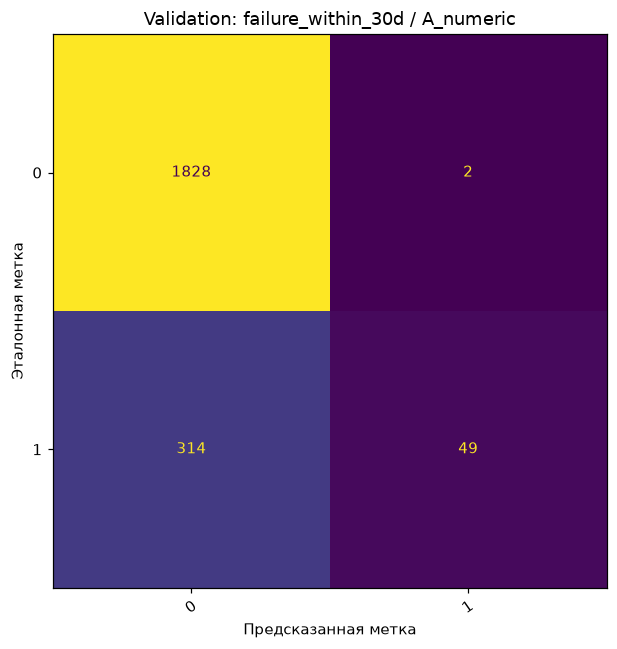

Ошибок validation: **316**.

,id,y_true,y_pred,probability_0,probability_1,predicted_probability,operator_log,equipment,severity
0,1242,1,0,0.937576,0.062424,0.937576,Зафиксирован устойчивый рост температуры корпу...,FV-40,medium
1,2425,1,0,0.910561,0.089439,0.910561,Зафиксирован устойчивый рост температуры корпу...,PN-200,medium
2,2141,1,0,0.888098,0.111902,0.888098,Зафиксирован устойчивый рост температуры корпу...,CP-500,medium
3,112,1,0,0.884521,0.115479,0.884521,Оператор отмечает нарастающий гул в зоне подши...,CP-500,medium
4,10787,1,0,0.882251,0.117749,0.882251,Зафиксирован устойчивый рост температуры корпу...,PN-300,medium
5,14331,1,0,0.877731,0.122269,0.877731,Зафиксирован устойчивый рост температуры корпу...,TR-90,medium
6,6283,1,0,0.868003,0.131997,0.868003,Обнаружены следы утечки в зоне уплотнения и сн...,PN-200,medium
7,3021,1,0,0.866629,0.133371,0.866629,Оператор отмечает нарастающий гул в зоне подши...,PN-200,medium
8,13228,1,0,0.864475,0.135525,0.864475,Зафиксирован устойчивый рост температуры корпу...,PN-200,medium
9,3185,1,0,0.858144,0.141856,0.858144,После выхода на режим появилась повышенная виб...,FV-40,medium


### failure_within_30d / A_tabular_restricted

,precision,recall,f1-score,support
0,0.853807,0.998907,0.920675,1830.000000
1,0.961538,0.137741,0.240964,363.000000
accuracy,0.856361,0.856361,0.856361,0.856361
macro avg,0.907673,0.568324,0.580819,2193.000000
weighted avg,0.871639,0.856361,0.808165,2193.000000


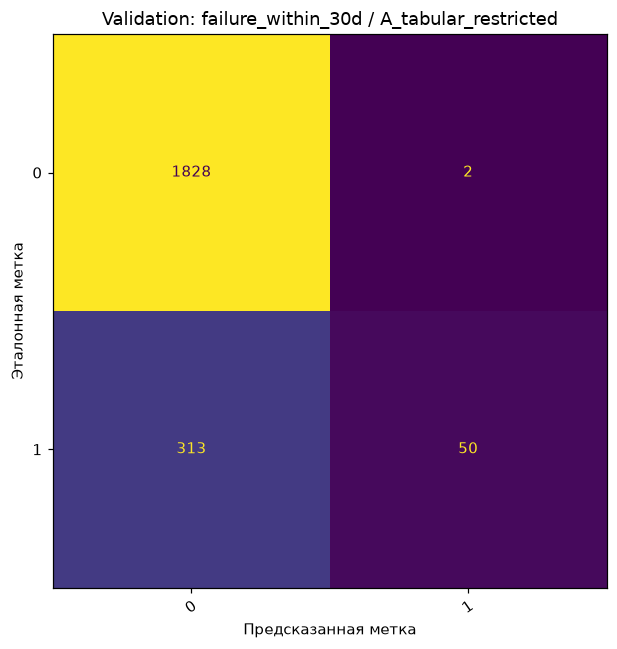

Ошибок validation: **315**.

,id,y_true,y_pred,probability_0,probability_1,predicted_probability,operator_log,equipment,severity
0,1242,1,0,0.935308,0.064692,0.935308,Зафиксирован устойчивый рост температуры корпу...,FV-40,medium
1,2425,1,0,0.908561,0.091439,0.908561,Зафиксирован устойчивый рост температуры корпу...,PN-200,medium
2,2141,1,0,0.894949,0.105051,0.894949,Зафиксирован устойчивый рост температуры корпу...,CP-500,medium
3,112,1,0,0.883045,0.116955,0.883045,Оператор отмечает нарастающий гул в зоне подши...,CP-500,medium
4,10787,1,0,0.881041,0.118959,0.881041,Зафиксирован устойчивый рост температуры корпу...,PN-300,medium
5,14331,1,0,0.879895,0.120105,0.879895,Зафиксирован устойчивый рост температуры корпу...,TR-90,medium
6,6283,1,0,0.872313,0.127687,0.872313,Обнаружены следы утечки в зоне уплотнения и сн...,PN-200,medium
7,3021,1,0,0.858111,0.141889,0.858111,Оператор отмечает нарастающий гул в зоне подши...,PN-200,medium
8,13228,1,0,0.856739,0.143261,0.856739,Зафиксирован устойчивый рост температуры корпу...,PN-200,medium
9,9637,1,0,0.853631,0.146369,0.853631,Обнаружены следы утечки в зоне уплотнения и сн...,TR-90,medium


### failure_within_30d / T0_tfidf

,precision,recall,f1-score,support
0,0.840074,0.987432,0.907812,1830.000000
1,0.452381,0.052342,0.093827,363.000000
accuracy,0.832649,0.832649,0.832649,0.832649
macro avg,0.646228,0.519887,0.500820,2193.000000
weighted avg,0.775901,0.832649,0.773076,2193.000000


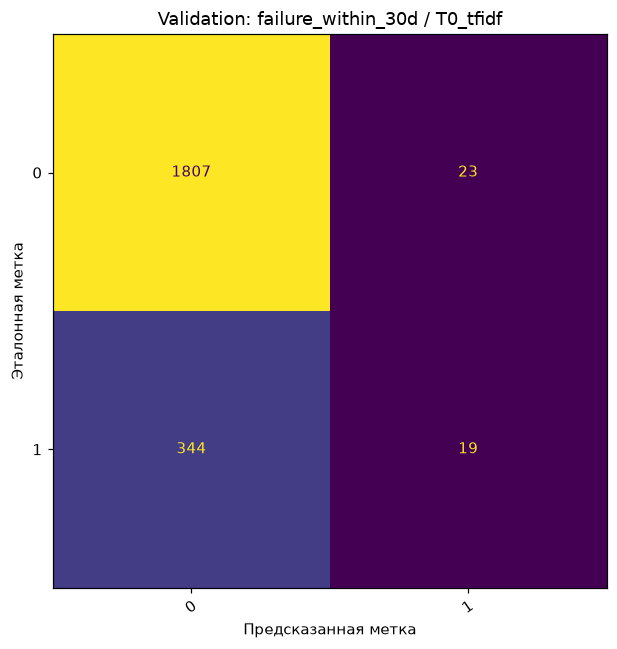

,class,feature,coefficient,direction
0,1,нет,-1.573437,negative
1,1,оборудования,-1.573437,negative
2,1,стабильна,-1.573437,negative
3,1,шумов,-1.573437,negative
4,1,работа,-1.573437,negative
5,1,посторонних,-1.573437,negative
6,1,52,-0.416577,negative
7,1,64,-0.347362,negative
8,1,нагрузка,-0.313175,negative
9,1,56,-0.287179,negative


Ошибок validation: **367**.

,id,y_true,y_pred,probability_0,probability_1,predicted_probability,operator_log,equipment,severity
0,7590,1,0,0.892719,0.107281,0.892719,Обнаружены следы утечки в зоне уплотнения и сн...,TR-90,medium
1,5475,1,0,0.892719,0.107281,0.892719,Обнаружены следы утечки в зоне уплотнения и сн...,TR-90,high
2,3899,1,0,0.892719,0.107281,0.892719,Обнаружены следы утечки в зоне уплотнения и сн...,PN-300,medium
3,3622,1,0,0.875282,0.124718,0.875282,После выхода на режим появилась повышенная виб...,PN-300,medium
4,4660,1,0,0.875282,0.124718,0.875282,После выхода на режим появилась повышенная виб...,FV-40,medium
5,469,1,0,0.874079,0.125921,0.874079,Обнаружены следы утечки в зоне уплотнения и сн...,PN-300,medium
6,2810,1,0,0.874079,0.125921,0.874079,Обнаружены следы утечки в зоне уплотнения и сн...,CP-500,medium
7,1096,1,0,0.874079,0.125921,0.874079,Обнаружены следы утечки в зоне уплотнения и сн...,PN-300,medium
8,125,1,0,0.874079,0.125921,0.874079,Обнаружены следы утечки в зоне уплотнения и сн...,PN-300,medium
9,7196,1,0,0.874079,0.125921,0.874079,Обнаружены следы утечки в зоне уплотнения и сн...,PN-300,medium


### fault_type / A_numeric

,precision,recall,f1-score,support
bearing_wear,0.717131,0.705882,0.711462,255.000000
cavitation,0.859091,0.851351,0.855204,222.000000
imbalance,0.632075,0.577586,0.603604,232.000000
normal,0.883019,0.931343,0.906538,1005.000000
overheat,0.951613,0.936508,0.944000,252.000000
seal_leak,0.638614,0.568282,0.601399,227.000000
accuracy,0.822617,0.822617,0.822617,0.822617
macro avg,0.780257,0.761826,0.770368,2193.000000
weighted avg,0.817343,0.822617,0.819330,2193.000000


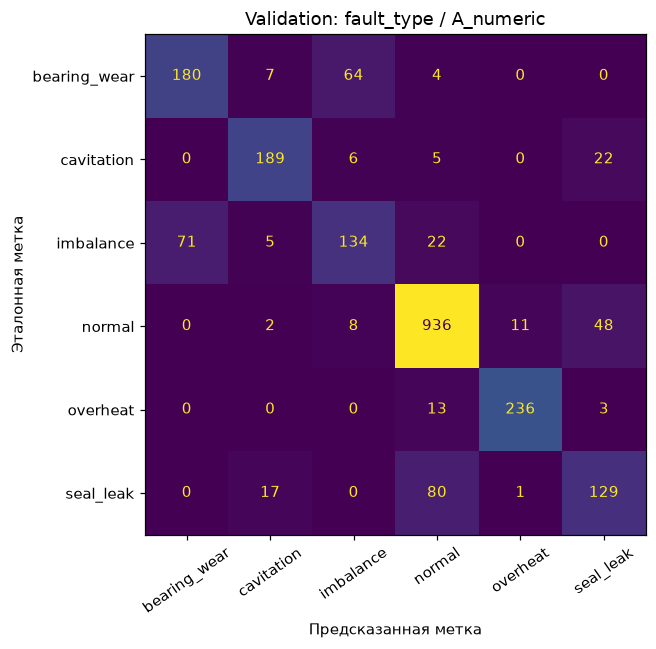

Ошибок validation: **389**.

,id,y_true,y_pred,probability_bearing_wear,probability_cavitation,probability_imbalance,probability_normal,probability_overheat,probability_seal_leak,predicted_probability,operator_log,equipment,severity
0,13696,seal_leak,normal,0.000005,0.000008,0.000251,0.980106,0.000705,0.018925,0.980106,Обнаружены следы утечки в зоне уплотнения и сн...,PN-200,low
1,3144,overheat,normal,0.000003,0.000001,0.000111,0.970742,0.019978,0.009164,0.970742,Зафиксирован устойчивый рост температуры корпу...,FV-40,low
2,2180,seal_leak,normal,0.000015,0.000021,0.000352,0.970206,0.000202,0.029205,0.970206,Обнаружены следы утечки в зоне уплотнения и сн...,CM-110,low
3,1072,seal_leak,normal,0.000010,0.000039,0.000553,0.968041,0.000157,0.031201,0.968041,Обнаружены следы утечки в зоне уплотнения и сн...,TR-90,low
4,3953,imbalance,cavitation,0.008750,0.956068,0.022113,0.000956,0.000010,0.012103,0.956068,После выхода на режим появилась повышенная виб...,PN-200,medium
5,11327,seal_leak,normal,0.000016,0.000087,0.000837,0.952209,0.004048,0.042803,0.952209,Обнаружены следы утечки в зоне уплотнения и сн...,CP-500,low
6,14740,seal_leak,normal,0.000519,0.000221,0.004945,0.944505,0.018198,0.031612,0.944505,Обнаружены следы утечки в зоне уплотнения и сн...,CP-500,low
7,3848,seal_leak,normal,0.001181,0.001362,0.023934,0.924796,0.000018,0.048708,0.924796,Обнаружены следы утечки в зоне уплотнения и сн...,CM-110,low
8,3062,seal_leak,normal,0.000090,0.000323,0.001414,0.921722,0.000018,0.076434,0.921722,Обнаружены следы утечки в зоне уплотнения и сн...,TR-90,low
9,9120,seal_leak,cavitation,0.000345,0.916824,0.001919,0.002409,0.000012,0.078491,0.916824,Обнаружены следы утечки в зоне уплотнения и сн...,FV-40,medium


### fault_type / A_tabular_restricted

,precision,recall,f1-score,support
bearing_wear,0.718876,0.701961,0.710317,255.000000
cavitation,0.867580,0.855856,0.861678,222.000000
imbalance,0.623256,0.577586,0.599553,232.000000
normal,0.877841,0.922388,0.899563,1005.000000
overheat,0.944223,0.940476,0.942346,252.000000
seal_leak,0.620690,0.555066,0.586047,227.000000
accuracy,0.817601,0.817601,0.817601,0.817601
macro avg,0.775411,0.758889,0.766584,2193.000000
weighted avg,0.812395,0.817601,0.814448,2193.000000


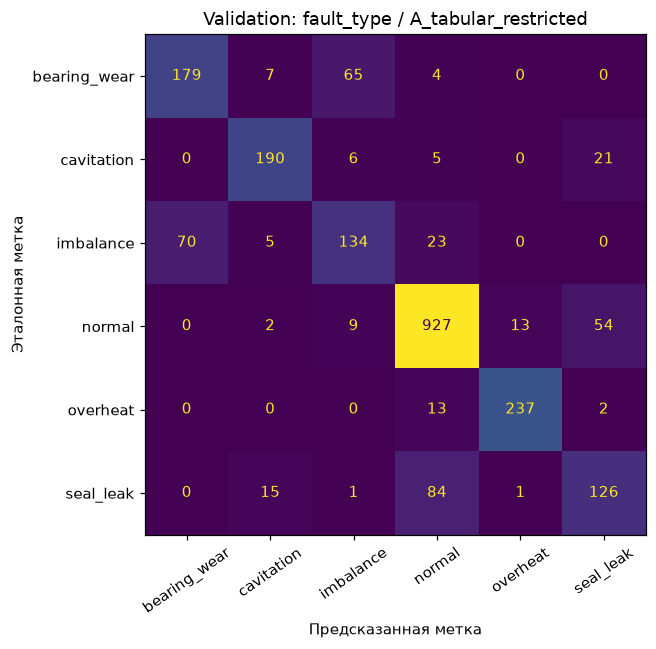

Ошибок validation: **400**.

,id,y_true,y_pred,probability_bearing_wear,probability_cavitation,probability_imbalance,probability_normal,probability_overheat,probability_seal_leak,predicted_probability,operator_log,equipment,severity
0,13696,seal_leak,normal,0.000005,0.000007,0.000303,0.982370,0.000892,0.016424,0.982370,Обнаружены следы утечки в зоне уплотнения и сн...,PN-200,low
1,1072,seal_leak,normal,0.000007,0.000031,0.000491,0.970850,0.000123,0.028498,0.970850,Обнаружены следы утечки в зоне уплотнения и сн...,TR-90,low
2,2180,seal_leak,normal,0.000013,0.000024,0.000349,0.970380,0.000200,0.029034,0.970380,Обнаружены следы утечки в зоне уплотнения и сн...,CM-110,low
3,3144,overheat,normal,0.000003,0.000001,0.000122,0.970161,0.021895,0.007819,0.970161,Зафиксирован устойчивый рост температуры корпу...,FV-40,low
4,11327,seal_leak,normal,0.000012,0.000067,0.000536,0.964472,0.002726,0.032188,0.964472,Обнаружены следы утечки в зоне уплотнения и сн...,CP-500,low
5,3953,imbalance,cavitation,0.009275,0.955010,0.024109,0.000994,0.000013,0.010599,0.955010,После выхода на режим появилась повышенная виб...,PN-200,medium
6,14740,seal_leak,normal,0.000427,0.000207,0.003942,0.952391,0.014019,0.029013,0.952391,Обнаружены следы утечки в зоне уплотнения и сн...,CP-500,low
7,9120,seal_leak,cavitation,0.000272,0.944693,0.001700,0.002248,0.000009,0.051078,0.944693,Обнаружены следы утечки в зоне уплотнения и сн...,FV-40,medium
8,1145,seal_leak,normal,0.000556,0.001272,0.011321,0.924518,0.000063,0.062270,0.924518,Обнаружены следы утечки в зоне уплотнения и сн...,PN-200,low
9,11835,seal_leak,normal,0.000819,0.001450,0.004373,0.923515,0.000019,0.069823,0.923515,Обнаружены следы утечки в зоне уплотнения и сн...,PN-300,low


### fault_type / T0_tfidf

,precision,recall,f1-score,support
bearing_wear,1.0,1.0,1.0,255.0
cavitation,1.0,1.0,1.0,222.0
imbalance,1.0,1.0,1.0,232.0
normal,1.0,1.0,1.0,1005.0
overheat,1.0,1.0,1.0,252.0
seal_leak,1.0,1.0,1.0,227.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,2193.0
weighted avg,1.0,1.0,1.0,2193.0


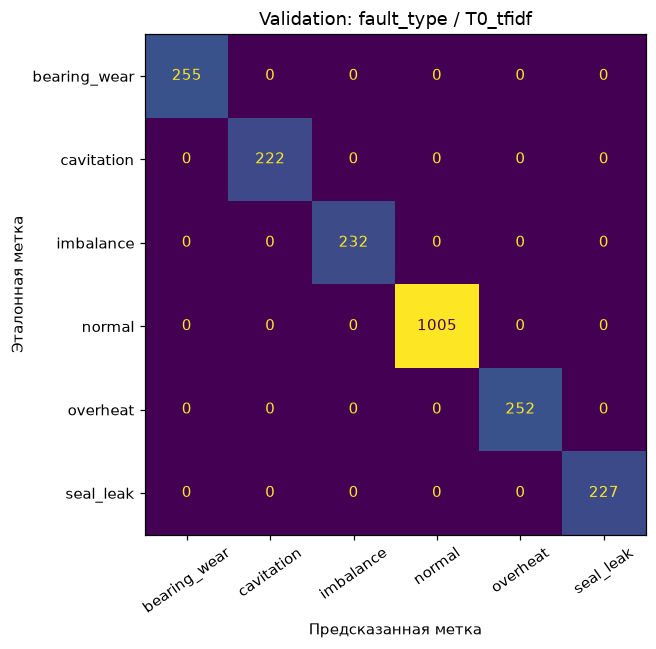

,class,feature,coefficient,direction
0,bearing_wear,вибрация,-0.485852,negative
1,bearing_wear,нет,-0.468207,negative
2,bearing_wear,стабильна,-0.468207,negative
3,bearing_wear,шумов,-0.468207,negative
4,bearing_wear,работа,-0.468207,negative
...,...,...,...,...
115,seal_leak,давления,1.892255,positive
116,seal_leak,уплотнения,1.892255,positive
117,seal_leak,снижение,1.892255,positive
118,seal_leak,следы,1.892255,positive


Ошибок validation: **0**.

Коэффициенты описывают модель, не причинное влияние. Положительный бинарный коэффициент поддерживает класс отказа 1. Старые запуски и их записи MLflow не изменяются.

In [13]:
selected_predictions = {}
diagnostic_root = batch_directory / "diagnostics"
for row in diagnostic_records.to_dict("records"):
    run_directory = PROJECT_ROOT / row["run_path"]
    diagnostic_directory = diagnostic_root / row["run_id"]
    diagnostic_directory.mkdir(parents=True)
    with (run_directory / "model.pkl").open("rb") as model_file:
        restored_pipeline = pickle.load(model_file)
    classes = restored_pipeline.named_steps["classifier"].classes_.tolist()
    run_manifest = json.loads(
        (run_directory / "manifest.json").read_text(encoding="utf-8")
    )
    features = run_manifest["features"]
    inputs = (
        validation["operator_log"]
        if "tfidf" in restored_pipeline.named_steps
        else validation[features]
    )
    predictions = pd.read_csv(
        run_directory / "validation_predictions.csv", dtype={"id": "string"}
    )
    assert predictions["id"].tolist() == validation["id"].tolist()
    probability_columns = [f"probability_{label}" for label in classes]
    np.testing.assert_allclose(
        restored_pipeline.predict_proba(inputs),
        predictions[probability_columns],
        atol=1e-12,
        rtol=1e-12,
    )
    selected_predictions[(row["target"], row["variant"])] = predictions
    report = pd.DataFrame(
        classification_report(
            predictions["y_true"],
            predictions["y_pred"],
            labels=classes,
            target_names=[str(label) for label in classes],
            output_dict=True,
            zero_division=0,
        )
    ).T
    report.to_csv(diagnostic_directory / "classification_report.csv")
    display(Markdown(f"### {row['target']} / {row['variant']}"))
    display(report)
    figure, axis = plt.subplots(figsize=(8, 6))
    ConfusionMatrixDisplay.from_predictions(
        predictions["y_true"],
        predictions["y_pred"],
        labels=classes,
        ax=axis,
        colorbar=False,
        xticks_rotation=35,
    )
    axis.set_xlabel("Предсказанная метка")
    axis.set_ylabel("Эталонная метка")
    axis.set_title(f"Validation: {row['target']} / {row['variant']}")
    figure.tight_layout()
    figure.savefig(diagnostic_directory / "confusion_matrix.png")
    plt.show()
    plt.close(figure)
    preprocessing = restored_pipeline.named_steps.get("tfidf")
    if preprocessing is None:
        preprocessing = restored_pipeline.named_steps["preprocessing"]
    feature_names = preprocessing.get_feature_names_out()
    coefficients = restored_pipeline.named_steps["classifier"].coef_
    coefficient_classes = classes[1:] if len(coefficients) == 1 else classes
    coefficient_records = []
    for label, values in zip(coefficient_classes, coefficients):
        for feature, value in zip(feature_names, values):
            coefficient_records.append(
                {"class": label, "feature": feature, "coefficient": value}
            )
    coefficient_table = pd.DataFrame(coefficient_records)
    coefficient_table.to_csv(
        diagnostic_directory / "coefficients.csv", index=False
    )
    if "tfidf" in restored_pipeline.named_steps:
        top_features = []
        for label, values in coefficient_table.groupby("class"):
            ordered = values.sort_values("coefficient")
            top_features.append(
                ordered.head(CONFIG["top_features"]).assign(
                    direction="negative"
                )
            )
            top_features.append(
                ordered.tail(CONFIG["top_features"]).assign(
                    direction="positive"
                )
            )
        top_features = pd.concat(top_features, ignore_index=True)
        top_features.to_csv(
            diagnostic_directory / "top_text_features.csv", index=False
        )
        display(top_features)
    errors = predictions.loc[
        predictions["y_true"].ne(predictions["y_pred"])
    ].copy()
    errors["predicted_probability"] = errors[probability_columns].max(axis=1)
    errors = errors.sort_values("predicted_probability", ascending=False)
    errors = errors.merge(
        validation[["id", "operator_log", "equipment", "severity"]],
        on="id",
        validate="one_to_one",
    )
    errors.head(CONFIG["error_examples"]).to_csv(
        diagnostic_directory / "error_examples.csv", index=False
    )
    display(Markdown(f"Ошибок validation: **{len(errors)}**."))
    if not errors.empty:
        display(errors.head(CONFIG["error_examples"]))
    subgroup_source = predictions.merge(
        validation[["id", "equipment", "severity"]],
        on="id",
        validate="one_to_one",
    )
    subgroup_records = []
    for grouping in ["equipment", "severity"]:
        for value, part in subgroup_source.groupby(grouping):
            subgroup_records.append(
                {
                    "grouping": grouping,
                    "value": value,
                    "records": len(part),
                    **baseline.classification_metrics(
                        part, classes, row["target"]
                    ),
                }
            )
    pd.DataFrame(subgroup_records).to_csv(
        diagnostic_directory / "subgroups.csv", index=False
    )
    if run_directory.parent.parent == batch_directory:
        mlflow.log_artifacts(
            str(diagnostic_directory),
            artifact_path="validation_diagnostics",
            run_id=row["run_id"],
        )
display(
    Markdown(
        "Коэффициенты описывают модель, не причинное влияние. "
        "Положительный бинарный коэффициент поддерживает класс отказа 1. "
        "Старые запуски и их записи MLflow не изменяются."
    )
)

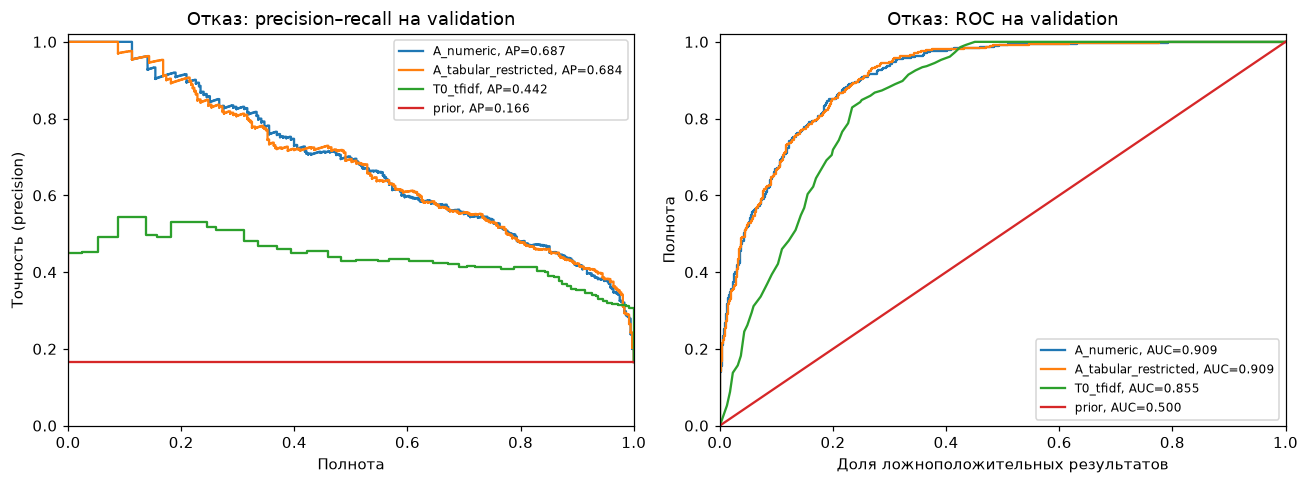

In [14]:
batch_figures = batch_directory / "figures"
batch_figures.mkdir(exist_ok=True)
figure, axes = plt.subplots(1, 2, figsize=(12, 4.5))
binary_target = "failure_within_30d"
for row in comparison.loc[comparison["target"].eq(binary_target)].to_dict(
    "records"
):
    predictions = pd.read_csv(
        PROJECT_ROOT / row["run_path"] / "validation_predictions.csv"
    )
    truth = predictions["y_true"]
    probabilities = predictions["probability_1"]
    precision, recall, _ = precision_recall_curve(truth, probabilities)
    false_positive_rate, true_positive_rate, _ = roc_curve(
        truth, probabilities
    )
    metrics = baseline.classification_metrics(
        predictions, [0, 1], binary_target
    )
    axes[0].step(
        recall,
        precision,
        where="post",
        label=f"{row['variant']}, AP={metrics['average_precision']:.3f}",
    )
    axes[1].plot(
        false_positive_rate,
        true_positive_rate,
        label=f"{row['variant']}, AUC={metrics['roc_auc']:.3f}",
    )
axes[0].set_title("Отказ: precision–recall на validation")
axes[0].set_xlabel("Полнота")
axes[0].set_ylabel("Точность (precision)")
axes[1].set_title("Отказ: ROC на validation")
axes[1].set_xlabel("Доля ложноположительных результатов")
axes[1].set_ylabel("Полнота")
for axis in axes:
    axis.set_xlim(0, 1)
    axis.set_ylim(0, 1.02)
    axis.legend(fontsize=8)
figure.tight_layout()
figure.savefig(batch_figures / "failure_validation_curves.png")
plt.show()
plt.close(figure)

## 10. Порог отказа по validation F2

Для трёх моделей, уже выбранных по AP, и бинарного контроля перебираем
уникальные вероятности плюс 0, 0,5 и 1. Отказ: `probability_1 >= threshold`.
Максимизируем F2; равенство до 12 знаков разрешаем по большей precision,
затем большему порогу. При отсутствии обоих классов расчёт завершается
ошибкой. Порог не выбирает конфигурацию и не меняет вероятности.

Сохраняем перебор, сравнение с 0,5, прогнозы train/validation, матрицы ошибок
и `model_f2.pkl`: `FixedThresholdClassifier` поверх готовой модели,
**без fit и без train+validation**. Исходный `model.pkl` сохраняется.
Параметры и результаты дописываются в те же записи MLflow; новых записей нет.


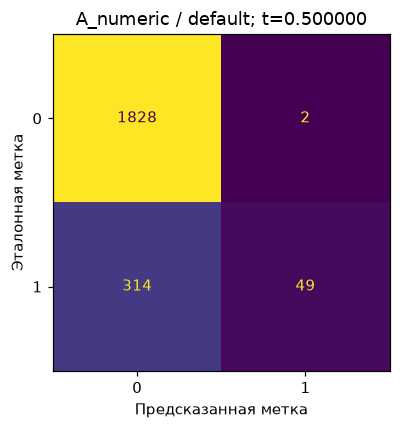

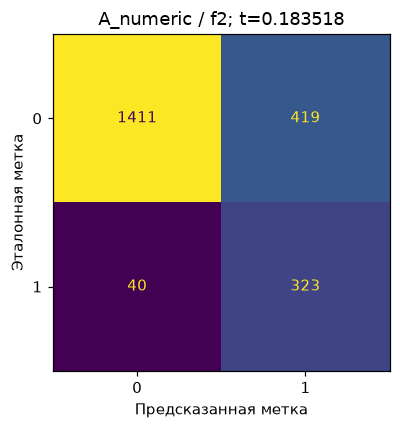

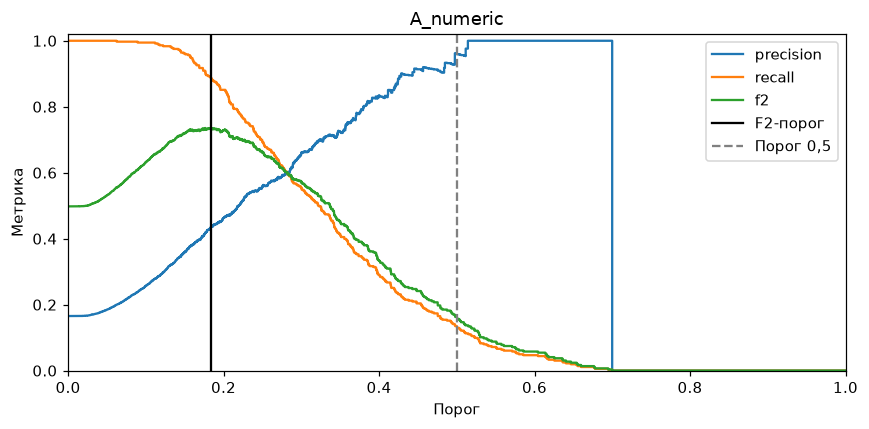

2026-10-17 23:13:02,415 INFO F2-порог A_numeric: 0.18351760029593853; F2 0.163007 -> 0.736098


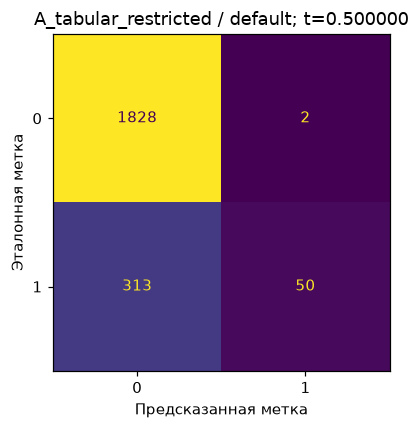

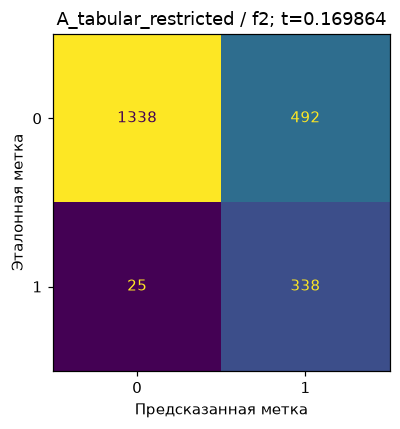

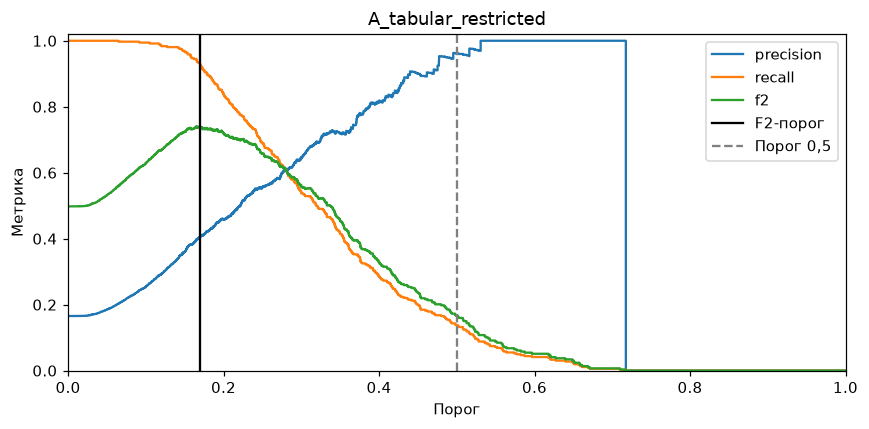

2026-10-17 23:13:02,917 INFO F2-порог A_tabular_restricted: 0.16986399252566761; F2 0.166223 -> 0.740578


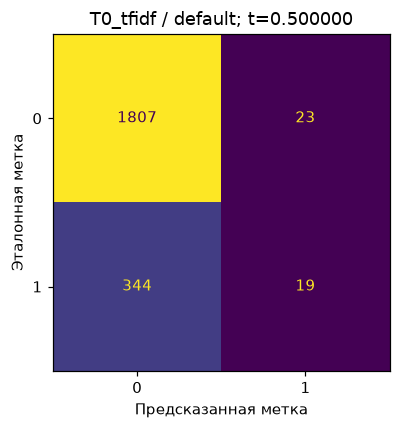

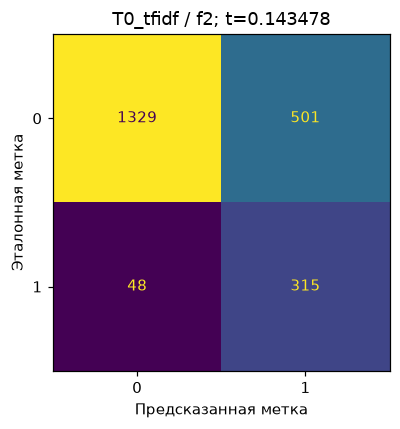

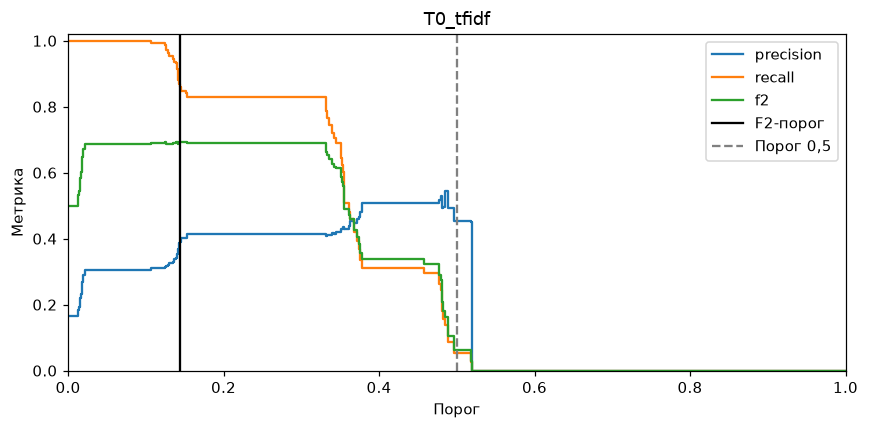

2026-10-17 23:13:03,525 INFO F2-порог T0_tfidf: 0.14347796574281224; F2 0.063588 -> 0.694444


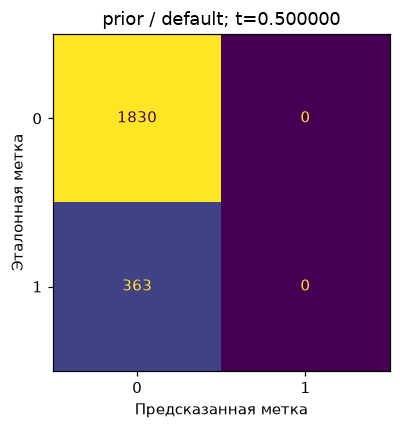

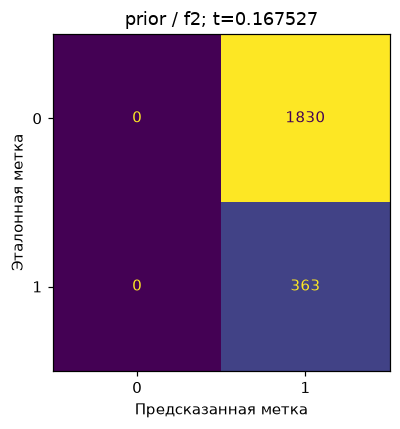

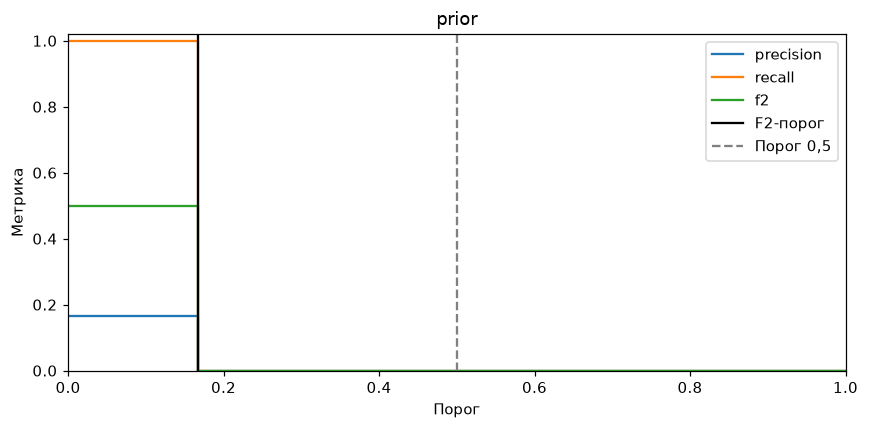

2026-10-17 23:13:03,940 INFO F2-порог prior: 0.16752698263725951; F2 0.000000 -> 0.497942


,run_id,run_path,variant,default_threshold,selected_threshold,candidate_count,default_precision,selected_precision,delta_precision,default_recall,...,delta_tp,default_fp,selected_fp,delta_fp,default_tn,selected_tn,delta_tn,default_fn,selected_fn,delta_fn
0,6e7bc1cb575846deab4b1c55c23bd47f,artifacts/experiments/logistic_restricted_f2_2...,A_numeric,0.5,0.183518,2196,0.960784,0.435310,-0.525474,0.134986,...,274,2,419,417,1828,1411,-417,314,40,-274
1,f330e64b34a2445cbb93211953ac6542,artifacts/experiments/logistic_restricted_f2_2...,A_tabular_restricted,0.5,0.169864,2196,0.961538,0.407229,-0.554310,0.137741,...,288,2,492,490,1828,1338,-490,313,25,-288
2,c0256cbf1a754a7d970c974b7923e481,artifacts/experiments/logistic_restricted_f2_2...,T0_tfidf,0.5,0.143478,62,0.452381,0.386029,-0.066352,0.052342,...,296,23,501,478,1807,1329,-478,344,48,-296
3,c2abf8dc3897473ab466615e5a546fb6,artifacts/experiments/logistic_restricted_f2_2...,prior,0.5,0.167527,4,0.000000,0.165527,0.165527,0.000000,...,363,0,1830,1830,1830,0,-1830,363,0,-363


In [15]:
threshold_config = CONFIG["threshold_selection"]
assert threshold_config["beta"] == 2
assert threshold_config["selection_split"] == "validation"
assert not threshold_config["refit"]
threshold_records = []
binary_models = comparison.loc[comparison["target"].eq(binary_target)]
assert len(binary_models) == CONFIG["expected_threshold_models"]
for row in binary_models.to_dict("records"):
    run_directory = PROJECT_ROOT / row["run_path"]
    threshold_directory = run_directory / "threshold_selection"
    threshold_directory.mkdir()
    run_manifest = json.loads(
        (run_directory / "manifest.json").read_text(encoding="utf-8")
    )
    with (run_directory / "model.pkl").open("rb") as model_file:
        fitted_model = pickle.load(model_file)
    validation_default = pd.read_csv(
        run_directory / "validation_predictions.csv",
        dtype={"id": "string"},
        float_precision="round_trip",
    )
    assert validation_default["id"].tolist() == validation["id"].tolist()
    np.testing.assert_array_equal(
        validation_default["y_true"], validation[binary_target]
    )
    best, threshold_curve = baseline.select_failure_threshold(
        validation_default["y_true"],
        validation_default["probability_1"],
        selection_decimals=threshold_config["selection_decimals"],
    )
    threshold_curve.to_csv(
        threshold_directory / "threshold_search.csv", index=False
    )
    default_counts = threshold_curve.loc[
        threshold_curve["threshold"].eq(CONFIG["binary_threshold"])
    ].iloc[0]
    threshold_record = {
        "run_id": row["run_id"],
        "run_path": row["run_path"],
        "variant": row["variant"],
        "default_threshold": CONFIG["binary_threshold"],
        "selected_threshold": best["threshold"],
        "candidate_count": len(threshold_curve),
    }
    wrapper = FixedThresholdClassifier(
        estimator=fitted_model,
        threshold=best["threshold"],
        pos_label=threshold_config["positive_class"],
        response_method="predict_proba",
    )
    with (run_directory / "model_f2.pkl").open("wb") as model_file:
        pickle.dump(wrapper, model_file, protocol=pickle.HIGHEST_PROTOCOL)
    with (run_directory / "model_f2.pkl").open("rb") as model_file:
        restored_wrapper = pickle.load(model_file)
    threshold_metrics = {}
    for partition, sample in [("train", train), ("validation", validation)]:
        default_predictions = pd.read_csv(
            run_directory / f"{partition}_predictions.csv",
            dtype={"id": "string"},
            float_precision="round_trip",
        )
        inputs = (
            sample["operator_log"]
            if row["variant"] == "T0_tfidf"
            else sample[run_manifest["features"]]
        )
        classes = fitted_model.classes_.tolist()
        probability_columns = [f"probability_{label}" for label in classes]
        probabilities = restored_wrapper.predict_proba(inputs)
        np.testing.assert_array_equal(
            probabilities, fitted_model.predict_proba(inputs)
        )
        np.testing.assert_array_equal(
            probabilities, default_predictions[probability_columns].to_numpy()
        )
        assert default_predictions["id"].tolist() == sample["id"].tolist()
        tuned_predictions = baseline.prediction_table(
            sample["id"],
            sample[binary_target],
            probabilities,
            classes,
            binary_target,
            best["threshold"],
        )
        np.testing.assert_array_equal(
            restored_wrapper.predict(inputs), tuned_predictions["y_pred"]
        )
        tuned_predictions.to_csv(
            run_directory / f"{partition}_predictions_f2.csv", index=False
        )
        old_metrics = baseline.classification_metrics(
            default_predictions, classes, binary_target
        )
        new_metrics = baseline.classification_metrics(
            tuned_predictions, classes, binary_target
        )
        for metric in ["average_precision", "roc_auc", "log_loss"]:
            assert old_metrics[metric] == new_metrics[metric]
        threshold_metrics[partition] = {
            "default": old_metrics,
            "selected": new_metrics,
        }
        if partition == "validation":
            for metric in [
                "precision",
                "recall",
                "f1",
                "f2",
                "average_precision",
                "roc_auc",
            ]:
                threshold_record[f"default_{metric}"] = old_metrics[metric]
                threshold_record[f"selected_{metric}"] = new_metrics[metric]
                threshold_record[f"delta_{metric}"] = (
                    new_metrics[metric] - old_metrics[metric]
                )
            for count in ["tp", "fp", "tn", "fn"]:
                threshold_record[f"default_{count}"] = int(
                    default_counts[count]
                )
                threshold_record[f"selected_{count}"] = best[count]
                threshold_record[f"delta_{count}"] = best[count] - int(
                    default_counts[count]
                )
            report = pd.DataFrame(
                classification_report(
                    tuned_predictions["y_true"],
                    tuned_predictions["y_pred"],
                    labels=classes,
                    output_dict=True,
                    zero_division=0,
                )
            ).T
            report.to_csv(threshold_directory / "classification_report_f2.csv")
    for name, counts in [("default", default_counts), ("f2", best)]:
        matrix = np.array(
            [[counts["tn"], counts["fp"]], [counts["fn"], counts["tp"]]],
            dtype=int,
        )
        pd.DataFrame(matrix, index=[0, 1], columns=[0, 1]).to_csv(
            threshold_directory / f"confusion_matrix_{name}.csv"
        )
        figure, axis = plt.subplots(figsize=(5, 4))
        ConfusionMatrixDisplay(matrix, display_labels=[0, 1]).plot(
            ax=axis, colorbar=False
        )
        axis.set_xlabel("Предсказанная метка")
        axis.set_ylabel("Эталонная метка")
        axis.set_title(
            f"{row['variant']} / {name}; t={counts['threshold']:.6f}"
        )
        figure.tight_layout()
        figure.savefig(threshold_directory / f"confusion_matrix_{name}.png")
        plt.show()
        plt.close(figure)
    figure, axis = plt.subplots(figsize=(8, 4))
    for metric in ["precision", "recall", "f2"]:
        axis.step(
            threshold_curve["threshold"],
            threshold_curve[metric],
            where="pre",
            label=metric,
        )
    axis.axvline(best["threshold"], label="F2-порог", color="black")
    axis.axvline(
        CONFIG["binary_threshold"],
        label="Порог 0,5",
        color="grey",
        linestyle="--",
    )
    axis.set(
        xlabel="Порог",
        ylabel="Метрика",
        title=row["variant"],
        xlim=(0, 1),
        ylim=(0, 1.02),
    )
    axis.legend()
    figure.tight_layout()
    figure.savefig(threshold_directory / "threshold_curve.png")
    plt.show()
    plt.close(figure)
    threshold_manifest = {
        **threshold_record,
        "selection": threshold_config,
        "metrics": threshold_metrics,
        "best_counts": best,
        "fitted_again": False,
        "limitation": "Конфигурация и порог выбраны на одной validation; "
        "оценки и интервалы могут быть оптимистичными.",
    }
    (threshold_directory / "manifest.json").write_text(
        json.dumps(threshold_manifest, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )
    run_manifest["threshold_selection"] = threshold_manifest
    (run_directory / "manifest.json").write_text(
        json.dumps(run_manifest, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )
    with mlflow.start_run(run_id=row["run_id"]):
        mlflow.log_params(
            {
                "f2_threshold": best["threshold"],
                "threshold_selection_metric": "f2",
                "threshold_selection_split": "validation",
                "threshold_refit": False,
            }
        )
        mlflow.log_metrics(
            {
                f"{partition}_{metric}_at_f2_threshold": value
                for partition, scores in threshold_metrics.items()
                for metric, value in scores["selected"].items()
                if value is not None
            }
        )
        mlflow.log_metrics(
            {
                f"validation_{name}": float(value)
                for name, value in threshold_record.items()
                if name.startswith(("delta_", "selected_"))
            }
        )
        mlflow.log_artifact(str(run_directory / "model_f2.pkl"))
        for partition in ["train", "validation"]:
            mlflow.log_artifact(
                str(run_directory / f"{partition}_predictions_f2.csv")
            )
        mlflow.log_artifact(str(run_directory / "manifest.json"))
        mlflow.log_artifacts(
            str(threshold_directory), artifact_path="threshold_selection"
        )
    logger.info(
        "F2-порог %s: %.17g; F2 %.6f -> %.6f",
        row["variant"],
        best["threshold"],
        threshold_record["default_f2"],
        threshold_record["selected_f2"],
    )
    threshold_records.append(threshold_record)
    pd.DataFrame(threshold_records).to_csv(
        batch_directory / "threshold_comparison.csv", index=False
    )
threshold_results = pd.DataFrame(threshold_records)
display(threshold_results)

## 11. Парное сравнение F2: выбранный порог против 0,5

Четыре сравнения на тех же id и группах validation, по 2 000 повторов,
seed 42. В каждом повторе переносится группа целиком и используются
**фиксированные** метки двух порогов: порог не переоптимизируется.
Интервалы условны относительно выбора на той же validation и могут
быть оптимистичными. При нулевом знаменателе F2 принимается равной 0
(`zero_division=0`); число пропущенных повторов сохраняется явно.


In [16]:
threshold_bootstrap_records = []
for row in threshold_results.to_dict("records"):
    run_directory = PROJECT_ROOT / row["run_path"]
    default_predictions = pd.read_csv(
        run_directory / "validation_predictions.csv",
        dtype={"id": "string"},
        float_precision="round_trip",
    )
    tuned_predictions = pd.read_csv(
        run_directory / "validation_predictions_f2.csv",
        dtype={"id": "string"},
        float_precision="round_trip",
    )
    logger.info("Парное сравнение F2: %s", row["variant"])
    result = comparison_tools.paired_group_bootstrap(
        default_predictions,
        tuned_predictions,
        validation_membership,
        [0, 1],
        binary_target,
        metric="f2",
        **CONFIG["bootstrap"],
    )
    record = {
        "variant": row["variant"],
        "run_id": row["run_id"],
        "reference_threshold": CONFIG["binary_threshold"],
        "candidate_threshold": row["selected_threshold"],
        **result,
    }
    threshold_bootstrap_records.append(record)
    with mlflow.start_run(run_id=row["run_id"]):
        mlflow.log_metrics(
            {
                f"validation_f2_threshold_bootstrap_{name}": result[name]
                for name in [
                    "difference",
                    "lower_95",
                    "upper_95",
                    "valid_repeats",
                    "skipped_repeats",
                ]
                if result[name] is not None
            }
        )
    pd.DataFrame(threshold_bootstrap_records).to_csv(
        batch_directory / "threshold_bootstrap.csv", index=False
    )
threshold_bootstrap_results = pd.DataFrame(threshold_bootstrap_records)
assert (
    len(threshold_bootstrap_results)
    == CONFIG["expected_threshold_comparisons"]
)
display(threshold_bootstrap_results)

2026-10-17 23:13:03,959 INFO Парное сравнение F2: A_numeric


2026-10-17 23:13:07,626 INFO Парное сравнение F2: A_tabular_restricted


2026-10-17 23:13:11,357 INFO Парное сравнение F2: T0_tfidf


2026-10-17 23:13:15,042 INFO Парное сравнение F2: prior


,variant,run_id,reference_threshold,candidate_threshold,metric,reference_score,candidate_score,difference,lower_95,upper_95,groups,requested_repeats,valid_repeats,skipped_repeats,seed,direction
0,A_numeric,6e7bc1cb575846deab4b1c55c23bd47f,0.5,0.183518,f2,0.163007,0.736098,0.573091,0.506629,0.632744,59,2000,2000,0,42,candidate - reference
1,A_tabular_restricted,f330e64b34a2445cbb93211953ac6542,0.5,0.169864,f2,0.166223,0.740578,0.574355,0.507906,0.634963,59,2000,2000,0,42,candidate - reference
2,T0_tfidf,c0256cbf1a754a7d970c974b7923e481,0.5,0.143478,f2,0.063588,0.694444,0.630857,0.523864,0.714594,59,2000,2000,0,42,candidate - reference
3,prior,c2abf8dc3897473ab466615e5a546fb6,0.5,0.167527,f2,0.000000,0.497942,0.497942,0.389863,0.606979,59,2000,2000,0,42,candidate - reference


## 12. Итог и контроль сохранения

Полное выполнение использует только эту тетрадь и её конфигурацию. Модели обеих целей остаются независимыми. Test не оценивается.

Оба выбора используют одну validation: оценки и интервалы могут быть оптимистичными и не заменяют итоговую тестовую оценку.

In [17]:
assert data.file_sha256(membership_path) == CONFIG["membership_sha256"]
assert (
    data.file_sha256(PROJECT_ROOT / dataset_config["dataset"])
    == dataset_config["sha256"]
)
tracked_runs = mlflow.search_runs(
    experiment_ids=[experiment_id],
    filter_string=f"tags.batch_id = '{batch_id}'",
)
assert len(tracked_runs) == CONFIG["expected_new_runs"]
assert tracked_runs["status"].eq("FINISHED").all()
assert not list(batch_directory.rglob("*test*predictions*"))
assert (
    len(list(batch_directory.rglob("model.pkl")))
    == CONFIG["expected_new_runs"]
)
assert (
    len(list(batch_directory.rglob("model_f2.pkl")))
    == CONFIG["expected_threshold_models"]
)
tracked_runs.to_csv(batch_directory / "mlflow_runs.csv", index=False)
findings = [
    "# Результаты модельного эксперимента на validation",
    "",
    f"Группа запусков: `{batch_id}`.",
    "",
]
for row in selected.to_dict("records"):
    findings.append(
        f"- `{row['target']}` / `{row['variant']}`: "
        f"{row['selection_metric']}={row['selected_validation_score']:.6f}; "
        f"C={row['C']}, class_weight={row['class_weight']}; "
        "изменение относительно начальной настройки "
        f"{row['validation_improvement']:+.6f}."
    )
findings.extend(["", "## Выбор порога по F2", ""])
for row in threshold_results.to_dict("records"):
    findings.append(
        f"- `{row['variant']}`: порог {row['selected_threshold']:.17g}; "
        f"F2 {row['default_f2']:.6f} → {row['selected_f2']:.6f}; "
        f"recall {row['default_recall']:.6f} → {row['selected_recall']:.6f}; "
        f"precision {row['default_precision']:.6f} → "
        f"{row['selected_precision']:.6f}; "
        f"FN {row['default_fn']} → {row['selected_fn']}, "
        f"FP {row['default_fp']} → {row['selected_fp']}."
    )
findings.extend(["", "## F2: выбранный порог минус 0,5", ""])
for row in threshold_bootstrap_results.to_dict("records"):
    findings.append(
        f"- `{row['variant']}`: ΔF2={row['difference']:+.6f}; "
        f"95%-й интервал [{row['lower_95']:+.6f}; {row['upper_95']:+.6f}]; "
        f"повторов {row['valid_repeats']}, пропущено {row['skipped_repeats']}."
    )
findings.extend(["", "## Парные сравнения: candidate − reference", ""])
for row in bootstrap_results.to_dict("records"):
    interval = (
        f"[{row['lower_95']:+.6f}; {row['upper_95']:+.6f}]"
        if pd.notna(row["lower_95"])
        else "не определён"
    )
    findings.append(
        f"- {row['kind']} / `{row['target']}` / "
        f"`{row['candidate_variant']}` относительно "
        f"`{row['reference_variant']}`: "
        f"Δ={row['difference']:+.6f}, 95%-й интервал {interval}; "
        f"пригодных повторов {row['valid_repeats']}, "
        f"пропущено {row['skipped_repeats']}."
    )
findings.extend(
    [
        "",
        f"Обучено классификаторов: {len(new_results)}; "
        f"частотных контролей: {len(reference_results)}.",
        "",
        "required_route и severity исключены из входов "
        "по решению пользователя от 2026-10-17. "
        "Их значения не передаются классификаторам.",
        "",
        "Интервалы рассчитаны по группам точных журналов validation "
        "после выбора конфигураций и порогов на той же validation. "
        "Оценки и интервалы условны относительно выбора и могут быть "
        "оптимистичными; итоговую тестовую оценку они не заменяют. "
        "Шесть общих шаблонов ограничивают выводы о новых формулировках. "
        "AP рассчитана через average_precision_score. Test не оценивался.",
    ]
)
summary_text = "\n".join(findings)
(batch_directory / "summary.md").write_text(summary_text, encoding="utf-8")
manifest.update(
    {
        "status": "completed",
        "new_fit_count": len(new_results) + len(reference_results),
        "classifier_count": len(new_results),
        "search_candidate_count": len(search_results),
        "selected_count": len(selected),
        "reference_count": len(reference_results),
        "paired_comparison_count": len(bootstrap_results),
        "threshold_comparison_count": len(threshold_bootstrap_results),
        "threshold_model_count": len(threshold_results),
        "threshold_refit_count": 0,
        "selected_runs": selected["run_id"].tolist(),
        "duration_seconds": perf_counter() - started_clock,
    }
)
manifest_path.write_text(
    json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8"
)
display(Markdown(summary_text))
logger.info("Эксперимент завершён: %s", batch_directory)

# Результаты модельного эксперимента на validation

Группа запусков: `logistic_restricted_f2_20261017T201122_790479Z`.

- `failure_within_30d` / `A_numeric`: average_precision=0.687009; C=0.001, class_weight=none; изменение относительно начальной настройки +0.001399.
- `failure_within_30d` / `A_tabular_restricted`: average_precision=0.683601; C=0.001, class_weight=none; изменение относительно начальной настройки +0.008988.
- `failure_within_30d` / `T0_tfidf`: average_precision=0.442193; C=0.1, class_weight=none; изменение относительно начальной настройки +0.000904.
- `fault_type` / `A_numeric`: macro_f1=0.770368; C=0.1, class_weight=none; изменение относительно начальной настройки +0.002418.
- `fault_type` / `A_tabular_restricted`: macro_f1=0.766584; C=0.1, class_weight=none; изменение относительно начальной настройки +0.001300.
- `fault_type` / `T0_tfidf`: macro_f1=1.000000; C=0.1, class_weight=none; изменение относительно начальной настройки +0.000000.

## Выбор порога по F2

- `A_numeric`: порог 0.18351760029593853; F2 0.163007 → 0.736098; recall 0.134986 → 0.889807; precision 0.960784 → 0.435310; FN 314 → 40, FP 2 → 419.
- `A_tabular_restricted`: порог 0.16986399252566761; F2 0.166223 → 0.740578; recall 0.137741 → 0.931129; precision 0.961538 → 0.407229; FN 313 → 25, FP 2 → 492.
- `T0_tfidf`: порог 0.14347796574281224; F2 0.063588 → 0.694444; recall 0.052342 → 0.867769; precision 0.452381 → 0.386029; FN 344 → 48, FP 23 → 501.
- `prior`: порог 0.16752698263725951; F2 0.000000 → 0.497942; recall 0.000000 → 1.000000; precision 0.000000 → 0.165527; FN 363 → 0, FP 0 → 1830.

## F2: выбранный порог минус 0,5

- `A_numeric`: ΔF2=+0.573091; 95%-й интервал [+0.506629; +0.632744]; повторов 2000, пропущено 0.
- `A_tabular_restricted`: ΔF2=+0.574355; 95%-й интервал [+0.507906; +0.634963]; повторов 2000, пропущено 0.
- `T0_tfidf`: ΔF2=+0.630857; 95%-й интервал [+0.523864; +0.714594]; повторов 2000, пропущено 0.
- `prior`: ΔF2=+0.497942; 95%-й интервал [+0.389863; +0.606979]; повторов 2000, пропущено 0.

## Парные сравнения: candidate − reference

- extension / `failure_within_30d` / `A_numeric` относительно `A_numeric`: Δ=+0.001305, 95%-й интервал [-0.006388; +0.007711]; пригодных повторов 2000, пропущено 0.
- extension / `failure_within_30d` / `A_tabular_restricted` относительно `A_tabular_restricted`: Δ=+0.002639, 95%-й интервал [-0.004230; +0.009427]; пригодных повторов 2000, пропущено 0.
- extension / `fault_type` / `A_numeric` относительно `A_numeric`: Δ=+0.000000, 95%-й интервал [+0.000000; +0.000000]; пригодных повторов 2000, пропущено 0.
- extension / `fault_type` / `A_tabular_restricted` относительно `A_tabular_restricted`: Δ=+0.000000, 95%-й интервал [+0.000000; +0.000000]; пригодных повторов 2000, пропущено 0.
- text_vs_baseline / `failure_within_30d` / `T0_tfidf` относительно `A_numeric`: Δ=-0.244816, 95%-й интервал [-0.285191; -0.201154]; пригодных повторов 2000, пропущено 0.
- text_vs_baseline / `failure_within_30d` / `T0_tfidf` относительно `A_tabular_restricted`: Δ=-0.241408, 95%-й интервал [-0.281644; -0.197194]; пригодных повторов 2000, пропущено 0.
- text_vs_baseline / `failure_within_30d` / `T0_tfidf` относительно `prior`: Δ=+0.276666, 95%-й интервал [+0.199297; +0.348774]; пригодных повторов 2000, пропущено 0.
- text_vs_baseline / `fault_type` / `T0_tfidf` относительно `A_numeric`: Δ=+0.229632, 95%-й интервал [+0.216204; +0.263962]; пригодных повторов 2000, пропущено 0.
- text_vs_baseline / `fault_type` / `T0_tfidf` относительно `A_tabular_restricted`: Δ=+0.233416, 95%-й интервал [+0.220742; +0.265499]; пригодных повторов 2000, пропущено 0.
- text_vs_baseline / `fault_type` / `T0_tfidf` относительно `prior`: Δ=+0.895247, 95%-й интервал [+0.873183; +0.930498]; пригодных повторов 2000, пропущено 0.

Обучено классификаторов: 64; частотных контролей: 2.

required_route и severity исключены из входов по решению пользователя от 2026-10-17. Их значения не передаются классификаторам.

Интервалы рассчитаны по группам точных журналов validation после выбора конфигураций и порогов на той же validation. Оценки и интервалы условны относительно выбора и могут быть оптимистичными; итоговую тестовую оценку они не заменяют. Шесть общих шаблонов ограничивают выводы о новых формулировках. AP рассчитана через average_precision_score. Test не оценивался.

2026-10-17 23:13:18,812 INFO Эксперимент завершён: C:\Users\Mo\work\study\Магистратура\2к\1с\LLMs\artifacts\experiments\logistic_restricted_f2_20261017T201122_790479Z


## Завершение A/B: сохранённые модели, без нового обучения

Самостоятельный раздел ab-review выполняется в свежем ядре. Используем закреплённые train/validation и сохранённые вероятности; test не оценивается. AP и трапецеидальная PR-AUC представлены раздельно. Проверяем id, классы и воспроизведение вероятностей загруженной моделью.

Для выполнения только этого раздела: `uv run --no-sync python scripts/check_eda.py notebooks/experiments/01_logistic_regression.ipynb --tag ab-review --timeout 1800`. Полный Run All первых тетрадей может повторно запустить их исходное обучение.

In [1]:
import hashlib
import json
import platform
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import precision_recall_fscore_support
from threadpoolctl import threadpool_limits

REVIEW_ROOT = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(REVIEW_ROOT / "src"))

from industrial_maintenance.experiment_review import (
    align_predictions,
    load_cpu_predictor,
    review_metrics,
    subgroup_review,
    time_predictions,
)

REVIEW_ROOT = Path.cwd().resolve().parents[1]
assert (REVIEW_ROOT / "PROJECT.md").is_file()
REVIEW = json.loads(
    (REVIEW_ROOT / "configs/ab_review.json").read_text(encoding="utf-8")
)
FAMILY = "logistic"
DESTINATION = REVIEW_ROOT / REVIEW["output_root"] / FAMILY
DESTINATION.mkdir(exist_ok=True)
REVIEW_REUSE = (DESTINATION / "timings.csv").is_file()
DATA_CONFIG = json.loads(
    (REVIEW_ROOT / REVIEW["dataset_config"]).read_text(encoding="utf-8")
)
assert (
    hashlib.sha256(
        (REVIEW_ROOT / DATA_CONFIG["dataset"]).read_bytes()
    ).hexdigest()
    == DATA_CONFIG["sha256"]
)
assert (
    hashlib.sha256(
        (REVIEW_ROOT / REVIEW["membership"]).read_bytes()
    ).hexdigest()
    == REVIEW["membership_sha256"]
)
membership = pd.read_csv(
    REVIEW_ROOT / REVIEW["membership"], dtype={"id": "string"}
)
development_ids = membership.loc[
    membership["split"].isin(["train", "validation"])
]
raw = pd.read_csv(REVIEW_ROOT / DATA_CONFIG["dataset"], dtype={"id": "string"})
development = raw.merge(development_ids, on="id", validate="one_to_one")
del raw
train = development.loc[development["split"].eq("train")].copy()
validation = (
    development.loc[development["split"].eq("validation")]
    .copy()
    .reset_index(drop=True)
)
assert len(train) == 10655 and len(validation) == 2193
specifications = [
    spec for spec in REVIEW["models"] if spec["family"] == FAMILY
]
print(REVIEW["review_id"], FAMILY, len(specifications), "fit=0; test=нет")
display(
    pd.DataFrame(specifications)[
        ["key", "features", "threshold", "fit_seconds"]
    ]
)

ab_review_20261018T122826_185163Z logistic 6 fit=0; test=нет


,key,features,threshold,fit_seconds
0,logistic:A_numeric:failure_within_30d,"[operating_hours, temperature_c, vibration_mm_...",0.183518,0.032975
1,logistic:A_tabular_restricted:failure_within_30d,"[operating_hours, temperature_c, vibration_mm_...",0.169864,0.020165
2,logistic:T0_tfidf:failure_within_30d,[operator_log],0.143478,0.061119
3,logistic:A_numeric:fault_type,"[operating_hours, temperature_c, vibration_mm_...",NaN,0.037152
4,logistic:A_tabular_restricted:fault_type,"[operating_hours, temperature_c, vibration_mm_...",NaN,0.065157
5,logistic:T0_tfidf:fault_type,[operator_log],NaN,0.078002


### Метрики, редкость классов и кандидаты для разбора

Отказ — сохранённый F2-порог; диагноз — argmax. Размеры классов берём только из train. Список ошибок не считается содержательным разбором: отдельные аннотированные случаи и общие выводы добавляются ниже.

In [2]:
if REVIEW_REUSE:
    metrics = pd.read_csv(DESTINATION / "metrics.csv")
    subgroups = pd.read_csv(DESTINATION / "subgroups.csv")
    class_scores = pd.read_csv(DESTINATION / "classes.csv")
    errors = pd.read_csv(DESTINATION / "error_candidates.csv")
    display(metrics)
    display(class_scores)
    display(errors.head(8))
else:
    metric_rows = []
    subgroup_rows = []
    class_rows = []
    error_rows = []
    saved_predictions = {}
    for spec in specifications:
        directory = REVIEW_ROOT / spec["run_path"]
        target = spec["target"]
        classes = spec["classes"]
        prediction_files = {"default": "validation_predictions.csv"}
        if target == "failure_within_30d":
            prediction_files["f2"] = "validation_predictions_f2.csv"
        for rule, filename in prediction_files.items():
            predictions = align_predictions(
                pd.read_csv(directory / filename, dtype={"id": "string"}),
                validation,
                target,
                classes,
            )
            metric_rows.append(
                {
                    "key": spec["key"],
                    "family": FAMILY,
                    "target": target,
                    "variant": spec["variant"],
                    "rule": rule,
                    "fit_seconds": spec["fit_seconds"],
                    **review_metrics(predictions, classes, target),
                }
            )
            working_rule = (
                "f2" if target == "failure_within_30d" else "default"
            )
            if rule != working_rule:
                continue
            saved_predictions[spec["key"]] = predictions
            groups = subgroup_review(predictions, validation, classes, target)
            groups["key"] = spec["key"]
            groups["target"] = target
            subgroup_rows.extend(groups.to_dict("records"))
            precision, recall, f1, support = precision_recall_fscore_support(
                predictions["y_true"],
                predictions["y_pred"],
                labels=classes,
                zero_division=0,
            )
            for index, label in enumerate(classes):
                class_rows.append(
                    {
                        "key": spec["key"],
                        "target": target,
                        "class": label,
                        "train_count": int(train[target].eq(label).sum()),
                        "train_share": float(train[target].eq(label).mean()),
                        "validation_count": int(support[index]),
                        "precision": precision[index],
                        "recall": recall[index],
                        "f1": f1[index],
                    }
                )
            errors = predictions.loc[
                predictions["y_true"].ne(predictions["y_pred"])
            ].merge(validation, on="id", validate="one_to_one")
            errors["key"] = spec["key"]
            errors["target"] = target
            errors["rule"] = working_rule
            if target == "failure_within_30d":
                errors["error_type"] = np.where(
                    errors["y_true"].eq(1), "FN", "FP"
                )
                errors["threshold"] = spec["threshold"]
                errors["decision_margin"] = (
                    errors["probability_1"] - spec["threshold"]
                )
            else:
                errors["error_type"] = "wrong_diagnosis"
            error_rows.extend(errors.to_dict("records"))
    metrics = pd.DataFrame(metric_rows)
    subgroups = pd.DataFrame(subgroup_rows)
    class_scores = pd.DataFrame(class_rows)
    errors = pd.DataFrame(error_rows)
    metrics.to_csv(DESTINATION / "metrics.csv", index=False)
    subgroups.to_csv(DESTINATION / "subgroups.csv", index=False)
    class_scores.to_csv(DESTINATION / "classes.csv", index=False)
    errors.to_csv(DESTINATION / "error_candidates.csv", index=False)
    display(metrics)
    display(class_scores)
    display(errors.head(8))

,key,family,target,variant,rule,fit_seconds,accuracy,macro_f1,log_loss,precision,recall,f1,f2,roc_auc,average_precision,pr_auc_trapezoid
0,logistic:A_numeric:failure_within_30d,logistic,failure_within_30d,A_numeric,default,0.032975,0.855905,0.578579,0.319685,0.960784,0.134986,0.236715,0.163007,0.908966,0.687009,0.686538
1,logistic:A_numeric:failure_within_30d,logistic,failure_within_30d,A_numeric,f2,0.032975,0.790698,0.722360,0.319685,0.435310,0.889807,0.584615,0.736098,0.908966,0.687009,0.686538
2,logistic:A_tabular_restricted:failure_within_30d,logistic,failure_within_30d,A_tabular_restricted,default,0.020165,0.856361,0.580819,0.319736,0.961538,0.137741,0.240964,0.166223,0.909308,0.683601,0.683115
3,logistic:A_tabular_restricted:failure_within_30d,logistic,failure_within_30d,A_tabular_restricted,f2,0.020165,0.764250,0.702361,0.319736,0.407229,0.931129,0.566639,0.740578,0.909308,0.683601,0.683115
4,logistic:T0_tfidf:failure_within_30d,logistic,failure_within_30d,T0_tfidf,default,0.061119,0.832649,0.500820,0.313482,0.452381,0.052342,0.093827,0.063588,0.855282,0.442193,0.448112
5,logistic:T0_tfidf:failure_within_30d,logistic,failure_within_30d,T0_tfidf,f2,0.061119,0.749658,0.681582,0.313482,0.386029,0.867769,0.534351,0.694444,0.855282,0.442193,0.448112
6,logistic:A_numeric:fault_type,logistic,fault_type,A_numeric,default,0.037152,0.822617,0.770368,0.435911,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,logistic:A_tabular_restricted:fault_type,logistic,fault_type,A_tabular_restricted,default,0.065157,0.817601,0.766584,0.440586,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,logistic:T0_tfidf:fault_type,logistic,fault_type,T0_tfidf,default,0.078002,1.000000,1.000000,0.043574,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,key,target,class,train_count,train_share,validation_count,precision,recall,f1
0,logistic:A_numeric:failure_within_30d,failure_within_30d,0,8870,0.832473,1830,0.972433,0.771038,0.860104
1,logistic:A_numeric:failure_within_30d,failure_within_30d,1,1785,0.167527,363,0.435310,0.889807,0.584615
2,logistic:A_tabular_restricted:failure_within_30d,failure_within_30d,0,8870,0.832473,1830,0.981658,0.731148,0.838083
3,logistic:A_tabular_restricted:failure_within_30d,failure_within_30d,1,1785,0.167527,363,0.407229,0.931129,0.566639
4,logistic:T0_tfidf:failure_within_30d,failure_within_30d,0,8870,0.832473,1830,0.965142,0.726230,0.828812
5,logistic:T0_tfidf:failure_within_30d,failure_within_30d,1,1785,0.167527,363,0.386029,0.867769,0.534351
6,logistic:A_numeric:fault_type,fault_type,bearing_wear,1261,0.118348,255,0.717131,0.705882,0.711462
7,logistic:A_numeric:fault_type,fault_type,cavitation,1069,0.100328,222,0.859091,0.851351,0.855204
8,logistic:A_numeric:fault_type,fault_type,imbalance,1147,0.107649,232,0.632075,0.577586,0.603604
9,logistic:A_numeric:fault_type,fault_type,normal,4783,0.448897,1005,0.883019,0.931343,0.906538


,id,y_true,y_pred,probability_0,probability_1,equipment,operating_hours,temperature_c,vibration_mm_s,pressure_bar,...,rule,error_type,threshold,decision_margin,probability_bearing_wear,probability_cavitation,probability_imbalance,probability_normal,probability_overheat,probability_seal_leak
0,5,0,1,0.805333,0.194667,PN-200,1929,77.36,2.417,6.279,...,f2,FP,0.183518,0.011149,NaN,NaN,NaN,NaN,NaN,NaN
1,14,0,1,0.685027,0.314973,PN-200,1515,70.14,3.306,4.646,...,f2,FP,0.183518,0.131455,NaN,NaN,NaN,NaN,NaN,NaN
2,41,0,1,0.756168,0.243832,TR-90,950,57.60,3.802,4.103,...,f2,FP,0.183518,0.060315,NaN,NaN,NaN,NaN,NaN,NaN
3,85,0,1,0.687055,0.312945,TR-90,72,61.26,3.527,2.618,...,f2,FP,0.183518,0.129427,NaN,NaN,NaN,NaN,NaN,NaN
4,112,1,0,0.884521,0.115479,CP-500,424,59.33,6.429,7.500,...,f2,FN,0.183518,-0.068038,NaN,NaN,NaN,NaN,NaN,NaN
5,194,0,1,0.811173,0.188827,PN-200,559,68.80,5.674,6.705,...,f2,FP,0.183518,0.005309,NaN,NaN,NaN,NaN,NaN,NaN
6,196,0,1,0.690539,0.309461,FV-40,2308,69.04,2.832,5.069,...,f2,FP,0.183518,0.125944,NaN,NaN,NaN,NaN,NaN,NaN
7,201,0,1,0.664352,0.335648,PN-200,1609,68.57,3.059,4.247,...,f2,FP,0.183518,0.152131,NaN,NaN,NaN,NaN,NaN,NaN


### Сопоставимое тёплое применение на CPU

Одинаковый порядок 2 193 validation-объектов, пакеты 64, пять повторов после прогрева. Для одиночных запросов — первые 64 объекта, три повтора. Предобработка/токенизация включена, загрузка весов и чтение с диска исключены. Среднее время одиночного запроса — время серии / 64; это не p95. RF сохраняет один поток применения, остальным доступно до шести CPU-потоков. Денежная стоимость и память не измеряются. Историческое время fit — для выбранного кандидата, не цена всего поиска.

In [3]:
if REVIEW_REUSE:
    timings = pd.read_csv(DESTINATION / "timings.csv")
    display(timings)
else:
    timing_rows = []
    timing_samples = []
    for spec in specifications:
        predict, classes = load_cpu_predictor(
            REVIEW_ROOT, spec, REVIEW["cpu_threads"]
        )
        assert classes == spec["classes"]
        inputs = validation[spec["features"]].copy()
        if "equipment" in inputs:
            inputs["equipment"] = inputs["equipment"].astype(str)
            inputs["manual_id"] = inputs["manual_id"].astype(str)
        reference = saved_predictions[spec["key"]]
        expected = reference[
            [f"probability_{label}" for label in classes]
        ].to_numpy()
        with threadpool_limits(limits=REVIEW["cpu_threads"]):
            actual, batched = time_predictions(
                predict,
                inputs,
                REVIEW["batch_size"],
                REVIEW["timing_repeats"],
            )
            _, single = time_predictions(
                predict,
                inputs.iloc[: REVIEW["single_records"]],
                1,
                REVIEW["single_repeats"],
            )
        np.testing.assert_allclose(
            actual,
            expected,
            atol=REVIEW["prediction_atol"],
            rtol=REVIEW["prediction_rtol"],
        )
        for mode, result in [("batch", batched), ("single", single)]:
            timing_samples.append({"key": spec["key"], "mode": mode, **result})
        timing_rows.append(
            {
                "key": spec["key"],
                "fit_seconds": spec["fit_seconds"],
                "batch_records": batched["records"],
                "batch_size": batched["batch_size"],
                "batch_median_seconds": batched["median_seconds"],
                "batch_amortized_ms_per_record": batched[
                    "amortized_ms_per_record"
                ],
                "single_mean_request_ms": single["amortized_ms_per_record"],
                "probabilities_reproduced": True,
            }
        )
        del predict
    timings = pd.DataFrame(timing_rows)
    timings.to_csv(DESTINATION / "timings.csv", index=False)
    (DESTINATION / "timing_samples.json").write_text(
        json.dumps(
            {
                "processor": platform.processor(),
                "platform": platform.platform(),
                "cpu_thread_budget": REVIEW["cpu_threads"],
                "note": "RF: n_jobs=1; до шести CPU-потоков.",
                "samples": timing_samples,
            },
            indent=2,
            ensure_ascii=False,
        ),
        encoding="utf-8",
    )
    display(timings)

,key,fit_seconds,batch_records,batch_size,batch_median_seconds,batch_amortized_ms_per_record,single_mean_request_ms,probabilities_reproduced
0,logistic:A_numeric:failure_within_30d,0.032975,2193,64,0.033599,0.015321,0.939078,True
1,logistic:A_tabular_restricted:failure_within_30d,0.020165,2193,64,0.082635,0.037681,2.328978,True
2,logistic:T0_tfidf:failure_within_30d,0.061119,2193,64,0.026044,0.011876,0.414475,True
3,logistic:A_numeric:fault_type,0.037152,2193,64,0.035620,0.016243,0.989064,True
4,logistic:A_tabular_restricted:fault_type,0.065157,2193,64,0.084817,0.038676,2.360139,True
5,logistic:T0_tfidf:fault_type,0.078002,2193,64,0.028716,0.013094,0.411841,True
